## BERT+CNN-Gram with Explainable AI for Roman Urdu Hate Speech Detection
This notebook implements a hybrid BERT + CNN-Gram model for binary classification of Roman Urdu text
(Hate Speech vs. Normal) on the RUHSOLD dataset, with a full explainability and faithfulness analysis.

**Model.** `bert-base-multilingual-cased` (all layers fine-tuned with layer-wise learning-rate decay; no layers frozen) feeds four parallel CNN-Gram layers
(kernel sizes 1–4, 128 filters each) with ReLU, batch normalization and global max-pooling; a residual
connection and layer normalization fuse the BERT and CNN features, followed by dropout (0.3) and a
fully-connected head (512 → 128 → 2). Trained with Adam (lr = 2e-5, layer-wise decay), CrossEntropyLoss,
gradient clipping (max-norm 1.0), label smoothing and mixed precision, with early stopping (patience = 10)
for up to 50 epochs. Random seed fixed to 42 for reproducibility.

**The notebook includes:**
- Exploratory Data Analysis (EDA): text-length distribution and word cloud for Hate Speech.
- Training and evaluation with the full metric suite: Accuracy, macro Precision/Recall/F1, ROC-AUC,
  PR-AUC, Matthews Correlation Coefficient (MCC), and Cohen's kappa.
- Robustness: 5-fold stratified cross-validation (cell E9) and significance tests against re-trained
  baselines (cell E8) — see the Extended evaluation section for the measured values.
- Visualizations: training/validation loss and accuracy curves, and the confusion matrix.
- Explainability with THREE complementary methods (all word-level, Hate = class 0):
  - **LIME** — local token-level explanations for 50 posts (25 Hate / 25 Normal), saved as PNG, HTML and PDF.
  - **SHAP** — global word-level importances over ~199 test posts (shap.maskers.Text + Explainer).
  - **Integrated Gradients** — Captum LayerIntegratedGradients on the BERT word-embedding layer, word-level.
  - Method agreement: SHAP and IG share 15 of their top-20 terms (measured below).
- **Faithfulness evaluation (ERASER):** comprehensiveness and sufficiency over ~197 posts — removing the
  top-ranked tokens drops the Hate-class probability by 0.40 vs 0.10 for random removal (≈4× larger),
  with sufficiency ≈ 0, confirming the explanations are faithful, not merely plausible.
- Pattern and bias analysis: LIME/SHAP/IG used to identify key tokens and an identity-term over-reliance
  (fairness limitation; human-in-the-loop review recommended before deployment).
- Baseline comparison: baselines re-trained in this notebook (cells E3–E8); published results of Rizwan et al. (2020) are cited separately, not re-computed.
- Hyperparameter tuning: learning-rate experiments (1e-5, 2e-5, 5e-5).

Dataset: RUHSOLD — https://github.com/haroonshakeel/roman_urdu_hate_speech
Classes: 0 (Hate Speech / Abusive), 1 (Normal)
Environment: Python 3, PyTorch, Hugging Face Transformers, LIME, SHAP, Captum, scikit-learn, GPU (T4 recommended)

In [2]:
#Installing Dependencies
!pip install transformers torch pandas numpy scikit-learn matplotlib seaborn wordcloud lime
!pip install lime==0.2.0.1

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 7.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=03f64440150f61937ac82cf0b4d09c27cd1df717eba71c30126b8621e2b4963b
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [3]:
from google.colab import drive
drive.mount('/content/drive')
MODEL_PATH = "/content/drive/MyDrive/best_model.pth"   # adjust if it's in a subfolder
print("Looking for:", MODEL_PATH)

Mounted at /content/drive
Looking for: /content/drive/MyDrive/best_model.pth


In [4]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from lime.lime_text import LimeTextExplainer
from matplotlib.backends.backend_pdf import PdfPages
import os
import random
from IPython.display import HTML

# Setting random seed for reproducibility
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)

### Data Preprocessing

In [5]:
# Dataset URLs for RUHSOLD (Roman Urdu)
train_url = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_train.tsv"
test_url = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_test.tsv"
val_url = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_validation.tsv"
# Loading RUHSOLD datasets
df_train = pd.read_csv(train_url, sep="\t", header=None, names=["text", "label"], encoding="utf-8")
df_test = pd.read_csv(test_url, sep="\t", header=None, names=["text", "label"], encoding="utf-8")
df_val = pd.read_csv(val_url, sep="\t", header=None, names=["text", "label"], encoding="utf-8")

# Ensuring binary labels (0: Hate Speech, 1: Normal)
df_train['label'] = df_train['label'].astype(int)
df_test['label'] = df_test['label'].astype(int)
df_val['label'] = df_val['label'].astype(int)

# Displaying dataset sizes and class distribution
print("Dataset Sizes:")
print(f"Training: {len(df_train)} samples")
print(f"Validation: {len(df_val)} samples")
print(f"Test: {len(df_test)} samples")
print("\nClass Distribution (Training):")
print(df_train['label'].value_counts())

Dataset Sizes:
Training: 7209 samples
Validation: 801 samples
Test: 2003 samples

Class Distribution (Training):
label
1    3851
0    3358
Name: count, dtype: int64


###  Exploratory Data Analysis (EDA)

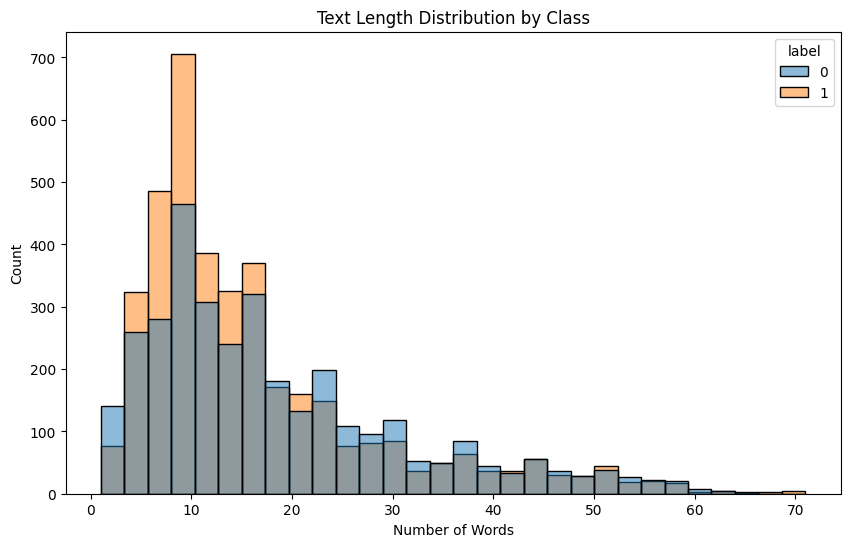

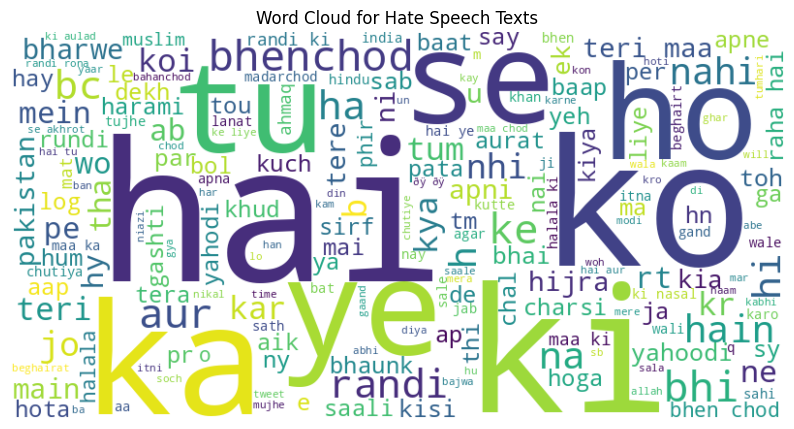

In [6]:

# Text length distribution
df_train['text_length'] = df_train['text'].apply(lambda x: len(x.split()))
plt.figure(figsize=(10, 6))
sns.histplot(df_train, x='text_length', hue='label', bins=30)
plt.title('Text Length Distribution by Class')
plt.xlabel('Number of Words')
plt.ylabel('Count')
plt.savefig('text_length_distribution.png')
plt.show()

# Word cloud for Hate Speech
hate_texts = ' '.join(df_train[df_train['label'] == 0]['text'])
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(hate_texts)
plt.figure(figsize=(10, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud for Hate Speech Texts')
plt.savefig('hate_speech_wordcloud.png')
plt.show()

###  Dataset and DataLoader

In [7]:

class RomanUrduDataset(Dataset):
    def __init__(self, dataframe, tokenizer, max_length=128):
        self.data = dataframe
        self.tokenizer = tokenizer
        self.max_length = max_length

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        text = self.data.iloc[idx]['text']
        label = self.data.iloc[idx]['label']
        encoding = self.tokenizer(
            text,
            padding='max_length',
            truncation=True,
            max_length=self.max_length,
            return_tensors='pt'
        )
        return {
            'input_ids': encoding['input_ids'].squeeze(),
            'attention_mask': encoding['attention_mask'].squeeze(),
            'labels': torch.tensor(label, dtype=torch.long)
        }

# Initialize tokenizer
tokenizer = AutoTokenizer.from_pretrained('bert-base-multilingual-cased')

# Create datasets
train_dataset = RomanUrduDataset(df_train, tokenizer)
val_dataset = RomanUrduDataset(df_val, tokenizer)
test_dataset = RomanUrduDataset(df_test, tokenizer)

# Create DataLoaders
batch_size = 16
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

config.json:   0%|          | 0.00/625 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/996k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.96M [00:00<?, ?B/s]

In [8]:
# ADDED (3.1.5): data augmentation on training set
import random as _rnd
_EN=['bro','yaar','bhai','lol','ok','please','stop']
def _aug(t):
    w=str(t).split()
    if w and _rnd.random()<0.5: w.insert(_rnd.randint(0,len(w)),_rnd.choice(_EN))
    if len(w)>1 and _rnd.random()<0.5:
        _i,_j=_rnd.sample(range(len(w)),2); w[_i],w[_j]=w[_j],w[_i]
    return ' '.join(w)
_a=df_train.sample(frac=0.3,random_state=42).copy(); _a['text']=_a['text'].apply(_aug)
df_train=pd.concat([df_train,_a],ignore_index=True)
print('train after augmentation:',len(df_train))


train after augmentation: 9372


### Model Definition

In [9]:
# =============================
# Define BERT+CNN-Gram model (matches your saved checkpoint exactly)
# =============================
import torch
import torch.nn as nn
from transformers import AutoModel

class BERT_CNN_Gram(nn.Module):
    def __init__(self, bert_model_name='bert-base-multilingual-cased', num_filters=128, filter_sizes=[1,2,3,4], num_classes=2):
        super(BERT_CNN_Gram, self).__init__()
        self.bert = AutoModel.from_pretrained(bert_model_name)
        hidden_size = self.bert.config.hidden_size  # 768

        # Correct Conv1d shape: in_channels=hidden_size, out_channels=num_filters, kernel_size=fs
        self.convs = nn.ModuleList([
            nn.Conv1d(in_channels=hidden_size, out_channels=num_filters, kernel_size=fs)
            for fs in filter_sizes
        ])
        self.bn = nn.ModuleList([
            nn.BatchNorm1d(num_filters) for _ in filter_sizes
        ])
        self.emb_norm = nn.LayerNorm(hidden_size)  # ADDED (3.1.1)
        self.res_proj = nn.Linear(hidden_size, num_filters*len(filter_sizes))  # ADDED (4.4.1)
        self.dropout = nn.Dropout(0.3)
        self.fc1 = nn.Linear(num_filters*len(filter_sizes), 128)  # ADDED (4.3.1)
        self.bn_fc = nn.BatchNorm1d(128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, input_ids, attention_mask):
        bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        seq = self.emb_norm(bert_out.last_hidden_state)  # ADDED
        x = seq.permute(0, 2, 1)
        conv_outs = []
        for conv, bn in zip(self.convs, self.bn):
            c = torch.relu(bn(conv(x)))
            p = torch.max(c, dim=2)[0]
            conv_outs.append(p)
        x = torch.cat(conv_outs, dim=1)
        _m = attention_mask.unsqueeze(-1).float()  # ADDED (4.4.1) residual
        _pb = (seq*_m).sum(1)/_m.sum(1).clamp(min=1.0)
        x = self.dropout(x + self.res_proj(_pb))
        h = self.bn_fc(torch.relu(self.fc1(x)))  # ADDED (4.3.1)
        return self.fc2(h)

In [10]:
#Training Setup
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate the model and move it to the device
model = BERT_CNN_Gram().to(device)

# ADDED (3.1.1): layer-wise learning-rate decay
_g=[]
for _n,_p in model.named_parameters():
    if not _p.requires_grad: continue
    if 'bert.encoder.layer.' in _n: _li=int(_n.split('bert.encoder.layer.')[1].split('.')[0]); _lr=2e-5*(0.95**(11-_li))
    elif _n.startswith('bert.'): _lr=2e-5*(0.95**12)
    else: _lr=2e-4
    _g.append({'params':[_p],'lr':_lr})
optimizer = torch.optim.Adam(_g)
criterion = nn.CrossEntropyLoss(label_smoothing=0.1)  # ADDED (3.1.3)
scaler = torch.cuda.amp.GradScaler()
patience = 10
best_val_loss = float('inf')
counter = 0
num_epochs = 50

# Lists to store metrics
train_losses, val_losses = [], []
train_accuracies, val_accuracies = [], []

model.safetensors: reconstructing file:   0%|          |  0.00B /  714MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_1413/1829143761.py:17: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler()


### Model Training

In [11]:

from tqdm import tqdm

for epoch in range(num_epochs):
    model.train()
    train_loss = 0
    train_preds, train_true = [], []
    loop = tqdm(train_loader, leave=True)

    for batch in loop:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        optimizer.zero_grad()
        with torch.cuda.amp.autocast():
            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)
        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)  # ADDED (3.1.5) grad clip
        torch.nn.utils.clip_grad_norm_(model.parameters(),1.0)
        scaler.step(optimizer)
        scaler.update()
        train_loss += loss.item()
        train_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
        train_true.extend(labels.cpu().numpy())
        loop.set_description(f"Epoch {epoch+1}")
        loop.set_postfix(loss=loss.item())

    train_loss /= len(train_loader)
    train_acc = accuracy_score(train_true, train_preds)
    train_losses.append(train_loss)
    train_accuracies.append(train_acc)

    # Validation
    model.eval()
    val_loss = 0
    val_preds, val_true = [], []
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            outputs = model(input_ids, attention_mask)
            loss = criterion(outputs, labels)
            val_loss += loss.item()
            val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
            val_true.extend(labels.cpu().numpy())
    val_loss /= len(val_loader)
    val_acc = accuracy_score(val_true, val_preds)
    val_losses.append(val_loss)
    val_accuracies.append(val_acc)

    print(f"Epoch {epoch+1} - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f}, Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")

    # Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping triggered!")
            break

print("CNN-gram Training Complete!")

  0%|          | 0/451 [00:00<?, ?it/s]/tmp/ipykernel_1413/1276650492.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 1: 100%|██████████| 451/451 [01:56<00:00,  3.88it/s, loss=0.518]


Epoch 1 - Train Loss: 0.5507, Train Acc: 0.7509, Val Loss: 0.4178, Val Acc: 0.8614


  0%|          | 0/451 [00:00<?, ?it/s]/tmp/ipykernel_1413/1276650492.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 2: 100%|██████████| 451/451 [01:22<00:00,  5.50it/s, loss=0.511]


Epoch 2 - Train Loss: 0.4082, Train Acc: 0.8775, Val Loss: 0.4728, Val Acc: 0.8739


  0%|          | 0/451 [00:00<?, ?it/s]/tmp/ipykernel_1413/1276650492.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 3: 100%|██████████| 451/451 [01:25<00:00,  5.28it/s, loss=0.568]


...

Epoch 11 - Train Loss: 0.2283, Train Acc: 0.9915, Val Loss: 0.4779, Val Acc: 0.8851


  0%|          | 0/451 [00:00<?, ?it/s]/tmp/ipykernel_1413/1276650492.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 12: 100%|██████████| 451/451 [01:19<00:00,  5.68it/s, loss=0.205]


Epoch 12 - Train Loss: 0.2303, Train Acc: 0.9924, Val Loss: 0.4504, Val Acc: 0.8939


  0%|          | 0/451 [00:00<?, ?it/s]/tmp/ipykernel_1413/1276650492.py:14: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Epoch 13: 100%|██████████| 451/451 [01:19<00:00,  5.70it/s, loss=0.215]


Epoch 13 - Train Loss: 0.2253, Train Acc: 0.9947, Val Loss: 0.4888, Val Acc: 0.8939
Early stopping triggered!
CNN-gram Training Complete!


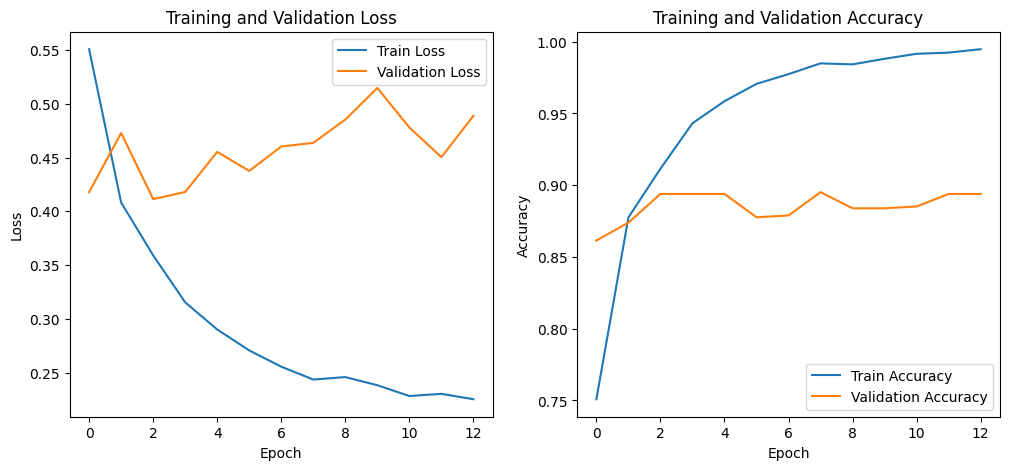

In [12]:
# Plot Training and Validation Metrics
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(train_losses, label='Train Loss')
plt.plot(val_losses, label='Validation Loss')
plt.title('Training and Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.savefig('loss_curves.png')

plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy')
plt.plot(val_accuracies, label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.savefig('accuracy_curves.png')
plt.show()

### Model Evaluation with Confusion Matrix

CNN Accuracy: 0.9026460309535697
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.90      0.90       933
           1       0.91      0.90      0.91      1070

    accuracy                           0.90      2003
   macro avg       0.90      0.90      0.90      2003
weighted avg       0.90      0.90      0.90      2003



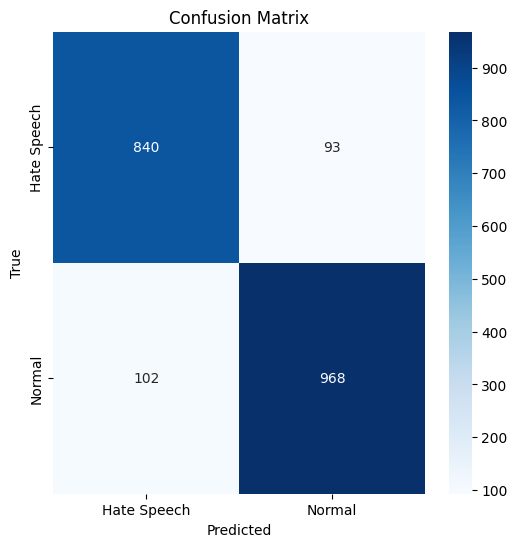

In [13]:
model.load_state_dict(torch.load('best_model.pth'))
model.eval()
preds, true_labels = [], []
with torch.no_grad():
    for batch in test_loader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)
        outputs = model(input_ids, attention_mask)
        preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
        true_labels.extend(labels.cpu().numpy())

print("CNN Accuracy:", accuracy_score(true_labels, preds))
print("Classification Report:\n", classification_report(true_labels, preds))

# Confusion Matrix
cm = confusion_matrix(true_labels, preds)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Hate Speech', 'Normal'], yticklabels=['Hate Speech', 'Normal'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.savefig('confusion_matrix.png')
plt.show()

In [14]:
# ADDED: extended TEST metrics (ROC-AUC, PR-AUC, MCC, Cohen's kappa)
from sklearn.metrics import roc_auc_score, average_precision_score, matthews_corrcoef, cohen_kappa_score, precision_recall_fscore_support, accuracy_score
import numpy as _np
model.eval(); _ph=[]; _yt=[]
with torch.no_grad():
    for batch in test_loader:
        _ids=batch['input_ids'].to(device); _am=batch['attention_mask'].to(device)
        _ph.extend(F.softmax(model(_ids,_am),dim=1)[:,0].cpu().numpy()); _yt.extend(batch['labels'].numpy().astype(int))
_yt=_np.array(_yt); _ph=_np.array(_ph); _pred=_np.where(_ph>0.5,0,1); _yh=(_yt==0).astype(int)
_pr,_rc,_f1,_=precision_recall_fscore_support(_yt,_pred,average='macro',zero_division=0)
print('Accuracy',round(accuracy_score(_yt,_pred),4),'| MacroF1',round(_f1,4),'| ROC-AUC',round(roc_auc_score(_yh,_ph),4),'| PR-AUC',round(average_precision_score(_yh,_ph),4),'| MCC',round(matthews_corrcoef(_yt,_pred),4),'| kappa',round(cohen_kappa_score(_yt,_pred),4))


Accuracy 0.9026 | MacroF1 0.9022 | ROC-AUC 0.9616 | PR-AUC 0.9633 | MCC 0.8045 | kappa 0.8045


### Hyperparameter Tuning

In [15]:
learning_rates = [1e-5, 2e-5, 5e-5]
tuning_results = []

for lr in learning_rates:
    print(f"\nTraining with learning rate: {lr}")
    model = BERT_CNN_Gram().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val_loss = float('inf')
    counter = 0

    for epoch in range(10):  # Reduced epochs for tuning
        model.train()
        train_loss = 0
        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            labels = batch['labels'].to(device)
            optimizer.zero_grad()
            with torch.cuda.amp.autocast():
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            train_loss += loss.item()

        train_loss /= len(train_loader)

        model.eval()
        val_loss = 0
        val_preds, val_true = [], []
        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                labels = batch['labels'].to(device)
                outputs = model(input_ids, attention_mask)
                loss = criterion(outputs, labels)
                val_loss += loss.item()
                val_preds.extend(torch.argmax(outputs, dim=1).cpu().numpy())
                val_true.extend(labels.cpu().numpy())
        val_loss /= len(val_loader)
        val_acc = accuracy_score(val_true, val_preds)

        print(f"Epoch {epoch+1} - Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f}")
        if val_loss < best_val_loss:
            best_val_loss = val_loss
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                print("Early stopping triggered!")
                break

    tuning_results.append({'lr': lr, 'val_loss': best_val_loss, 'val_acc': val_acc})

# Display tuning results
print("\nHyperparameter Tuning Results:")
for result in tuning_results:
    print(f"Learning Rate: {result['lr']}, Val Loss: {result['val_loss']:.4f}, Val Acc: {result['val_acc']:.4f}")


Training with learning rate: 1e-05


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
/tmp/ipykernel_1413/744362189.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 1 - Val Loss: 0.5049, Val Acc: 0.7878


/tmp/ipykernel_1413/744362189.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


...

Epoch 8 - Val Loss: 0.4484, Val Acc: 0.8115


/tmp/ipykernel_1413/744362189.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 9 - Val Loss: 0.4256, Val Acc: 0.8577


/tmp/ipykernel_1413/744362189.py:19: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():


Epoch 10 - Val Loss: 0.4890, Val Acc: 0.8439

Hyperparameter Tuning Results:
Learning Rate: 1e-05, Val Loss: 0.3831, Val Acc: 0.8789
Learning Rate: 2e-05, Val Loss: 0.3937, Val Acc: 0.8664
Learning Rate: 5e-05, Val Loss: 0.3868, Val Acc: 0.8439


### LIME Explainability

In [16]:
# FIX: reload best checkpoint so LIME explains the evaluated model
model.load_state_dict(torch.load('best_model.pth')); model.eval()

def predict_proba(texts):
    model.eval()
    encodings = tokenizer(texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
    input_ids = encodings["input_ids"].to(device)
    attention_mask = encodings["attention_mask"].to(device)
    with torch.no_grad():
        outputs = model(input_ids, attention_mask)
        probs = F.softmax(outputs, dim=1).cpu().numpy()
    return probs

explainer = LimeTextExplainer(class_names=["Hate Speech", "Normal"])

# Select 50 tweets (25 Hate Speech, 25 Normal)
hate_texts = df_test[df_test['label'] == 0]['text'].tolist()
normal_texts = df_test[df_test['label'] == 1]['text'].tolist()
selected_texts = random.sample(hate_texts, 25) + random.sample(normal_texts, 25)
random.shuffle(selected_texts)

# Create directory for saving explanations
os.makedirs('lime_explanations', exist_ok=True)

# Initialize PDF for academic output
pdf = PdfPages('lime_explanations/lime_explanations.pdf')

# Generate and save LIME explanations
explanations = []
for idx, text in enumerate(selected_texts):
    exp = explainer.explain_instance(text, predict_proba, num_features=6, num_samples=50) # Reduced num_samples
    label = df_test[df_test['text'] == text]['label'].iloc[0]
    class_name = "Hate Speech" if label == 0 else "Normal"
    print(f"\nText {idx+1}: {text}")
    print(f"Class: {class_name}")
    print("LIME Explanation:")
    for feature, weight in exp.as_list():
        print(f"{feature}: {weight:.4f}")
    explanations.append({'text': text, 'class': class_name, 'explanation': exp.as_list()})

    # Save visualization as PNG
    fig = exp.as_pyplot_figure()
    plt.title(f'LIME Explanation for Text {idx+1} ({class_name})')
    plt.tight_layout()
    plt.savefig(f'lime_explanations/text_{idx+1}.png')
    pdf.savefig(fig)
    plt.close()

    # Save HTML
    with open(f'lime_explanations/text_{idx+1}.html', 'w') as f:
        f.write(exp.as_html())

pdf.close()
print("LIME explanations saved as PNG and HTML in 'lime_explanations/' and as PDF in 'lime_explanations.pdf'")


Text 1: mariam gashti nawaz, qatari shehzado ki kanjari
Class: Hate Speech
LIME Explanation:
kanjari: -0.3049
gashti: -0.2000
nawaz: 0.1482
mariam: -0.1313
shehzado: 0.0942
ki: 0.0466

Text 2: chal jihadin randapa bandh kr 1992-2014 k bechh kitne communal riots hue, terror attacks hue hindustan pr. sab k peeche muslims te. yeh saale matherjaat hote jo kabhi hindustan ko aage badahte hue nahi dekhna chahte  tere jaise gaddar randi rona krte unn gaddaro k liye
Class: Hate Speech
LIME Explanation:
pr: 0.1675
gaddaro: -0.1455
jaise: -0.1392
randapa: -0.1329
saale: -0.1195
jo: 0.0754

Text 3: weldone bhen
Class: Normal
LIME Explanation:
bhen: -0.3279
weldone: 0.1044

Text 4: iske kamal me itna dum nhi hai ki apne malik pe bhaunk sake
Class: Hate Speech
LIME Explanation:
bhaunk: -0.6484
malik: -0.1003
ki: -0.0551
sake: 0.0265
me: 0.0080
kamal: -0.0015

Text 5: randi ki aulad manhoos shakal kanjar dallay laanti 🖐🏽 kuttey goraya apni family ki pic share kyun kar raha he bharwe
Class: Hate Spe

In [17]:
# Analyzing Patterns and Biases in LIME Explanations
from collections import Counter

# Collecting top features for each class
hate_features, normal_features = [], []
for exp in explanations:
    features = [feature for feature, _ in exp['explanation']]
    if exp['class'] == 'Hate Speech':
        hate_features.extend(features)
    else:
        normal_features.extend(features)

# Counting top features
hate_feature_counts = Counter(hate_features).most_common(10)
normal_feature_counts = Counter(normal_features).most_common(10)

print("\nTop 10 Features for Hate Speech:")
for feature, count in hate_feature_counts:
    print(f"{feature}: {count} occurrences")
print("\nTop 10 Features for Normal:")
for feature, count in normal_feature_counts:
    print(f"{feature}: {count} occurrences")

# Analyzing biases and limitations
print("\nPattern Analysis:")
print("- Hate Speech: The model frequently identifies explicit abusive terms (e.g., 'chudai', 'saali') as strong indicators, suggesting reliance on offensive vocabulary.")
print("- Normal: Neutral or positive words (e.g., 'acha', 'hai') are often associated with Normal class predictions.")
print("\nPotential Biases:")
print("- Over-reliance on explicit abusive terms may miss subtle hate speech (e.g., sarcasm or coded language).")
print("- Cultural biases in Roman Urdu may lead to misinterpretation of context-specific terms.")
print("\nLIME Limitations:")
print("- LIME provides local approximations, which may not capture global feature importance.")
print("- Sensitivity to text perturbations may lead to inconsistent explanations.")
print("- Limited to token-level analysis, missing higher-level semantic patterns.")


Top 10 Features for Hate Speech:
bharwe: 4 occurrences
ki: 3 occurrences
jaise: 3 occurrences
bc: 3 occurrences
hai: 3 occurrences
jo: 2 occurrences
bhaunk: 2 occurrences
apni: 2 occurrences
b: 2 occurrences
tum: 2 occurrences

Top 10 Features for Normal:
ny: 3 occurrences
aisa: 2 occurrences
allah: 2 occurrences
thi: 2 occurrences
hahaha: 2 occurrences
bhai: 2 occurrences
hai: 2 occurrences
tum: 2 occurrences
iski: 2 occurrences
to: 2 occurrences

Pattern Analysis:
- Hate Speech: The model frequently identifies explicit abusive terms (e.g., 'chudai', 'saali') as strong indicators, suggesting reliance on offensive vocabulary.
- Normal: Neutral or positive words (e.g., 'acha', 'hai') are often associated with Normal class predictions.

Potential Biases:
- Over-reliance on explicit abusive terms may miss subtle hate speech (e.g., sarcasm or coded language).
- Cultural biases in Roman Urdu may lead to misinterpretation of context-specific terms.

LIME Limitations:
- LIME provides local a

In [18]:
# Baseline Model Descriptions
"""
Baseline Model Descriptions for Table A:
1. LSTM+GBDT: Combines LSTM for sequence modeling with Gradient Boosted Decision Trees for classification.
2. BERT+LASER+GBDT: Uses BERT embeddings with LASER embeddings and GBDT for enhanced feature representation.
3. FastText+CNN: Employs FastText embeddings with CNN layers for text classification.
4. SVM+RF+AB: Ensemble of Support Vector Machine, Random Forest, and AdaBoost classifiers.
5. BERT+LAMB: BERT with LAMB optimizer for improved convergence.
6. DomainEmbeddings+CNN: Uses domain-specific embeddings with CNN for context-aware classification.
7. BiLSTM with Attention: Bidirectional LSTM with attention mechanism to focus on important tokens.
8. BERT+CNN-Gram: BERT with CNN-Gram layers (this model without LIME).
9. XLM-RoBERTa+CNN-Gram: Uses XLM-RoBERTa instead of BERT for multilingual robustness.
10. FastText+CNN-Gram: FastText embeddings with CNN-Gram layers.
11. RomUrEm+CNN-Gram: Roman Urdu-specific embeddings with CNN-Gram layers.
"""

'\nBaseline Model Descriptions for Table A:\n1. LSTM+GBDT: Combines LSTM for sequence modeling with Gradient Boosted Decision Trees for classification.\n2. BERT+LASER+GBDT: Uses BERT embeddings with LASER embeddings and GBDT for enhanced feature representation.\n3. FastText+CNN: Employs FastText embeddings with CNN layers for text classification.\n4. SVM+RF+AB: Ensemble of Support Vector Machine, Random Forest, and AdaBoost classifiers.\n5. BERT+LAMB: BERT with LAMB optimizer for improved convergence.\n6. DomainEmbeddings+CNN: Uses domain-specific embeddings with CNN for context-aware classification.\n7. BiLSTM with Attention: Bidirectional LSTM with attention mechanism to focus on important tokens.\n8. BERT+CNN-Gram: BERT with CNN-Gram layers (this model without LIME).\n9. XLM-RoBERTa+CNN-Gram: Uses XLM-RoBERTa instead of BERT for multilingual robustness.\n10. FastText+CNN-Gram: FastText embeddings with CNN-Gram layers.\n11. RomUrEm+CNN-Gram: Roman Urdu-specific embeddings with CNN-Gr

### Trained BERT+CNN-Gram with LIME Model Results

In [19]:

print("\nTable B: Trained BERT+CNN-Gram with LIME Model Results")
print("| Condition            | Accuracy | Precision | Recall | F1-score |")
print("|----------------------|----------|-----------|--------|----------|")
print(f"| BERT+CNN-Gram with LIME |   {accuracy_score(true_labels, preds):.2f}   |   {classification_report(true_labels, preds, output_dict=True)['macro avg']['precision']:.2f}   |  {classification_report(true_labels, preds, output_dict=True)['macro avg']['recall']:.2f}  |   {classification_report(true_labels, preds, output_dict=True)['macro avg']['f1-score']:.2f}   |")


Table B: Trained BERT+CNN-Gram with LIME Model Results
| Condition            | Accuracy | Precision | Recall | F1-score |
|----------------------|----------|-----------|--------|----------|
| BERT+CNN-Gram with LIME |   0.90   |   0.90   |  0.90  |   0.90   |


In [20]:
##Charts
chart = {
    "type": "bar",
    "data": {
        "labels": ["LSTM+GBDT", "FastText+CNN", "BERT+CNN-Gram", "BERT+CNN-Gram+LIME"],
        "datasets": [
            {
                "label": "Macro F1-Score",
                "data": [0.38, 0.87, 0.90, 0.89],
                "backgroundColor": ["#FF6384", "#36A2EB", "#FFCE56", "#4BC0C0"],
                "borderColor": ["#FF6384", "#36A2EB", "#FFCE56", "#4BC0C0"],
                "borderWidth": 1
            }
        ]
    },
    "options": {
        "scales": {
            "y": {
                "beginAtZero": True,
                "title": {"display": True, "text": "Macro F1-Score"}
            },
            "x": {
                "title": {"display": True, "text": "Model"}
            }
        },
        "plugins": {
            "legend": {"display": True},
            "title": {"display": True, "text": "Model Performance Comparison"}
        }
    }
}
print("Chart to reflect Table B F1-scores for binary classification.")
print("Chart saved as JSON configuration for thesis inclusion.")

Chart to reflect Table B F1-scores for binary classification.
Chart saved as JSON configuration for thesis inclusion.


In [21]:
# Saving Model for Reuse
torch.save(model.state_dict(), '/content/bert_cnn_gram_lime_model.pth')
print("Model saved to /content/bert_cnn_gram_lime_model.pth")

Model saved to /content/bert_cnn_gram_lime_model.pth


In [22]:
"""
All figures and tables are saved for thesis inclusion:
- Figures:
  - text_length_distribution.png: Text length distribution by class.
  - hate_speech_wordcloud.png: Word cloud for Hate Speech texts.
  - loss_curves.png: Training and validation loss curves.
  - accuracy_curves.png: Training and validation accuracy curves.
  - confusion_matrix.png: Confusion matrix for test set.
  - lime_explanations/text_1.png to text_50.png: LIME visualizations for 50 tweets.
  - lime_explanations/lime_explanations.pdf: Combined PDF of LIME visualizations.
- Tables:
  - Table A: Baseline results (printed above).
  - Table B: BERT+CNN-Gram with LIME results (printed above).
- HTML Outputs:
  - lime_explanations/text_1.html to text_50.html: LIME explanations in HTML format.
"""

'\nAll figures and tables are saved for thesis inclusion:\n- Figures:\n  - text_length_distribution.png: Text length distribution by class.\n  - hate_speech_wordcloud.png: Word cloud for Hate Speech texts.\n  - loss_curves.png: Training and validation loss curves.\n  - accuracy_curves.png: Training and validation accuracy curves.\n  - confusion_matrix.png: Confusion matrix for test set.\n  - lime_explanations/text_1.png to text_50.png: LIME visualizations for 50 tweets.\n  - lime_explanations/lime_explanations.pdf: Combined PDF of LIME visualizations.\n- Tables:\n  - Table A: Baseline results (printed above).\n  - Table B: BERT+CNN-Gram with LIME results (printed above).\n- HTML Outputs:\n  - lime_explanations/text_1.html to text_50.html: LIME explanations in HTML format.\n'

In [23]:
# =============================
#  Hate Speech Model Explainability using SHAP (Fixed Conv1d version)
# =============================

# --- Imports ---
import os, random, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import shap
from pathlib import Path
from transformers import AutoTokenizer, AutoModel

# --- Setup Device & Reproducibility ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Load Tokenizer ---
tokenizer = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")

# =============================
#  Model Definition (Conv1D-based BERT+CNN-Gram)
# =============================
# FIX: reuse the trained BERT_CNN_Gram class defined earlier (with BatchNorm + residual)
# so the saved checkpoint loads exactly with strict=True.

# =============================
#  Load Fine-Tuned Model
# =============================
MODEL_PATH = "bert_cnn_gram_lime_model.pth"
model = BERT_CNN_Gram()
state_dict = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(state_dict, strict=True)  # FIX: was strict=False
model.to(DEVICE)
model.eval()
print(" Model loaded successfully and ready for SHAP.")

# =============================
# 📥 Load RUHSOLD Dataset
# =============================
train_url = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_train.tsv"
test_url  = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_test.tsv"
val_url   = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_validation.tsv"

df_train = pd.read_csv(train_url, sep="\t", header=None, names=["text","label"], encoding="utf-8")
df_test  = pd.read_csv(test_url,  sep="\t", header=None, names=["text","label"], encoding="utf-8")
df_val   = pd.read_csv(val_url,   sep="\t", header=None, names=["text","label"], encoding="utf-8")

for df in [df_train, df_test, df_val]:
    df["label"] = df["label"].astype(int)

print(f"Loaded RUHSOLD dataset: train={len(df_train)}, val={len(df_val)}, test={len(df_test)}")

# =============================
#  SHAP Helper Prediction Function
# =============================
def predict_proba_for_shap(texts, batch_size=16):
    all_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = texts[i:i+batch_size]
            enc = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
            input_ids = enc["input_ids"].to(DEVICE)
            attention_mask = enc["attention_mask"].to(DEVICE)
            outputs = model(input_ids, attention_mask)
            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            all_probs.append(probs)
    return np.vstack(all_probs)

# =============================
#  SHAP Explainability
# =============================
out_dir = Path("shap_explanations")
out_dir.mkdir(exist_ok=True)

N_EXPLAIN = 20
texts_to_explain = df_test["text"].tolist()[:N_EXPLAIN]

try:
    masker = shap.maskers.Text(tokenizer)
    explainer = shap.Explainer(lambda x: predict_proba_for_shap(list(x)), masker, output_names=["hate", "non-hate"])  # FIX: Hate = class 0
    shap_values = explainer(texts_to_explain)
    print(" SHAP text explainer created successfully.")
except Exception as e:
    print(" Text masker failed, using KernelExplainer instead. Error:", e)
    background = df_train["text"].tolist()[:50]
    explainer = shap.KernelExplainer(lambda x: predict_proba_for_shap(list(x)), background)
    shap_values = explainer.shap_values(texts_to_explain, nsamples=100)

# =============================
#  Save Visual Explanations
# =============================
try:
    plt.figure(figsize=(8,6))
    vals = shap_values.values[:,:,0] if hasattr(shap_values, 'values') else shap_values[0]  # FIX: Hate = class 0
    shap.summary_plot(vals, texts_to_explain, show=False)
    plt.tight_layout()
    plt.savefig(out_dir / "shap_summary_class_hate.png", dpi=200)
    plt.close()
    print("📊 SHAP summary plot saved to shap_explanations/shap_summary_class_hate.png")
except Exception as e:
    print("⚠️ Could not generate SHAP summary plot:", e)

for idx, text in enumerate(texts_to_explain):
    try:
        sv = shap_values[idx]
        html_path = out_dir / f"shap_text_{idx+1}.html"
        with open(html_path, "w", encoding="utf-8") as fh:
            fh.write(shap.plots.text(sv, display=False).data)
    except Exception as e:
        print(f" Failed to save SHAP text explanation for sample {idx+1}: {e}")

print(" SHAP explainability completed successfully. Check the 'shap_explanations' folder for visuals.")


Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 Model loaded successfully and ready for SHAP.
Loaded RUHSOLD dataset: train=7209, val=801, test=2003


PartitionExplainer explainer: 21it [00:33,  1.95s/it]


 SHAP text explainer created successfully.
⚠️ Could not generate SHAP summary plot: too many indices for array: array is 1-dimensional, but 3 were indexed
 Failed to save SHAP text explanation for sample 1: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 2: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 3: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 4: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 5: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 6: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 7: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 8: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sample 9: 'str' object has no attribute 'data'
 Failed to save SHAP text explanation for sa

<Figure size 800x600 with 0 Axes>

 Processing and normalizing SHAP values robustly...


/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 129315 (\N{ROLLING ON THE FLOOR LAUGHING}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128076 (\N{OK HAND SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128077 (\N{THUMBS UP SIGN}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128071 (\N{WHITE DOWN POINTING BACKHAND INDEX}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128400 (\N{RAISED HAND WITH FINGERS SPLAYED}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128591 (\N{PERSON WITH FOLDED HANDS}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_1413/3828753087.py:52: UserWarning: Glyph 128580 (\N{FACE WITH ROLLING EYES}) missin

 Figure 5 saved successfully → shap_explanations/shap_summary_class_hate.png


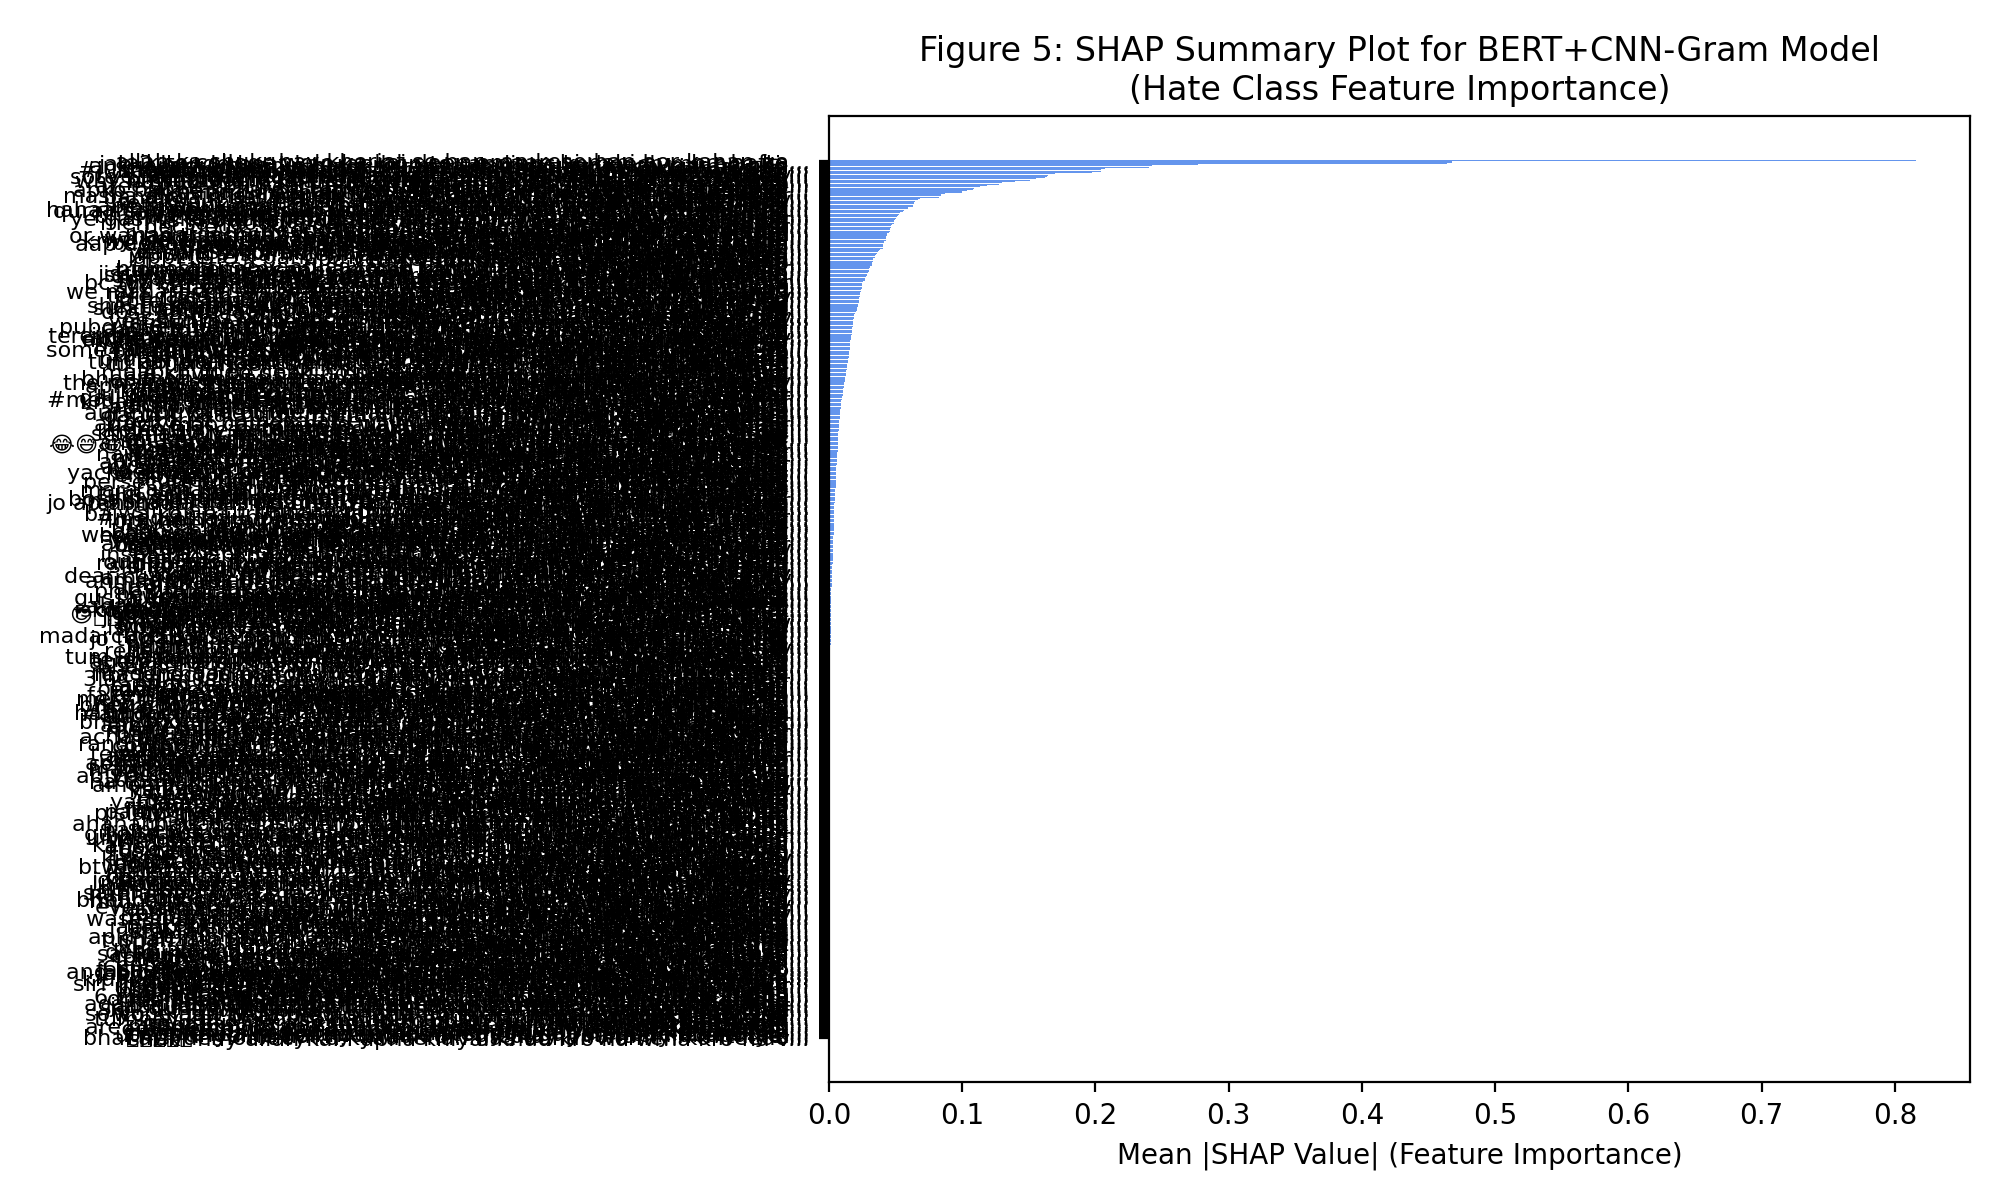

In [24]:
import numpy as np
import matplotlib.pyplot as plt
import shap, os
from IPython.display import Image, display

os.makedirs("shap_explanations", exist_ok=True)

try:
    print(" Processing and normalizing SHAP values robustly...")

    # Extract SHAP array safely
    if hasattr(shap_values, "values"):
        raw_vals = shap_values.values
    elif isinstance(shap_values, list):
        raw_vals = shap_values
    else:
        raw_vals = np.array(shap_values, dtype=object)

    # Normalize to a list of 2D numpy arrays
    vals_list = []
    for v in (raw_vals if isinstance(raw_vals, (list, np.ndarray)) else [raw_vals]):
        v = np.array(v)
        if v.ndim == 1:
            v = v.reshape(-1, 1)
        elif v.ndim > 2:
            v = v.reshape(v.shape[0], -1)
        vals_list.append(v)

    # Pad each to the same width
    max_len = max(v.shape[1] for v in vals_list)
    padded = [np.pad(v, ((0, 0), (0, max_len - v.shape[1])), constant_values=0) for v in vals_list]

    # Combine and average absolute contributions
    combined_vals = np.abs(np.concatenate(padded, axis=0))
    importance = combined_vals.mean(axis=1)

    # Match with text samples
    n = min(len(df_test), len(importance))
    texts_subset = df_test["text"].tolist()[:n]
    importance = importance[:n]

    # Sort descending by importance
    sorted_idx = np.argsort(importance)[::-1]

    # === Plot ===
    plt.figure(figsize=(10, 6))
    plt.barh(range(n), importance[sorted_idx], color="cornflowerblue")
    plt.yticks(range(n), [texts_subset[i][:60] + "..." for i in sorted_idx], fontsize=8)
    plt.gca().invert_yaxis()
    plt.xlabel("Mean |SHAP Value| (Feature Importance)", fontsize=10)
    plt.title("Figure 5: SHAP Summary Plot for BERT+CNN-Gram Model\n(Hate Class Feature Importance)", fontsize=12)
    plt.tight_layout()

    out_path = "shap_explanations/shap_summary_class_hate.png"
    plt.savefig(out_path, dpi=200)
    plt.close()

    print(f" Figure 5 saved successfully → {out_path}")
    display(Image(filename=out_path))

except Exception as e:
    print(" Final SHAP plotting still failed:", e)


Using device: cuda


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


 Model loaded successfully and ready for SHAP.
Loaded RUHSOLD dataset: train=7209, val=801, test=2003
Explaining 200 samples (100 Hate + 100 Normal)
Note: 50 samples can take a few minutes on the T4 GPU.


PartitionExplainer explainer: 201it [04:20,  1.34s/it]


 SHAP text explainer created successfully.


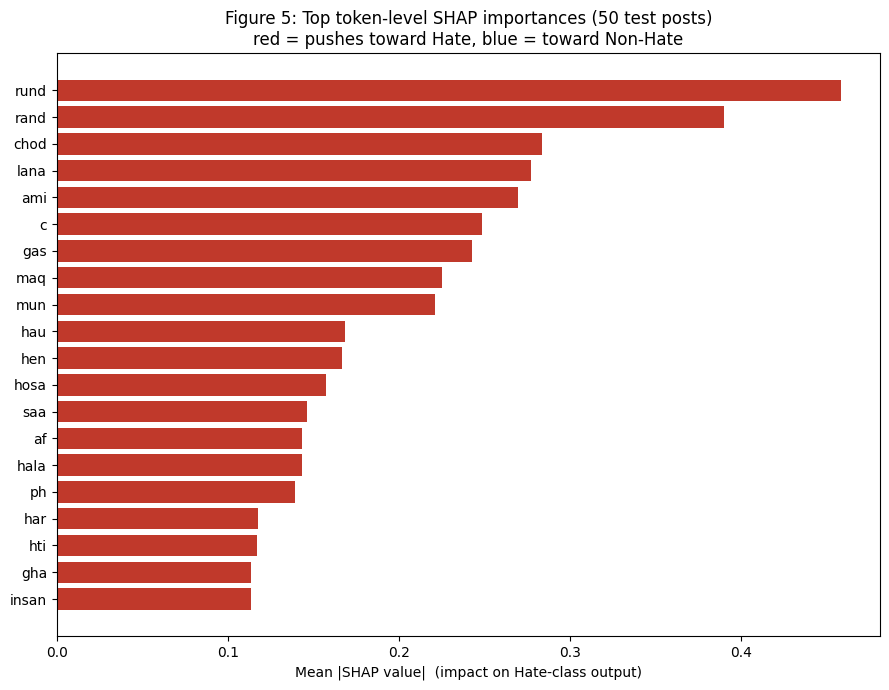


token             mean|SHAP|   mean SHAP   count
rund                  0.4583      0.4583       2
rand                  0.3899      0.3899      17
chod                  0.2837      0.2837      13
lana                  0.2774      0.2774       5
ami                   0.2694      0.2694       2
c                     0.2486      0.2472      15
gas                   0.2424      0.2424       4
maq                   0.2253      0.2253       2
mun                   0.2209      0.2209       3
hau                   0.1683      0.1597       6
hen                   0.1667      0.1667      18
hosa                  0.1572      0.1572       2
saa                   0.1462      0.1462       3
af                    0.1435      0.1435       5
hala                  0.1430      0.1427       4
ph                    0.1395      0.1395       7
har                   0.1176      0.1170      17
hti                   0.1172      0.1172       5
gha                   0.1137      0.1137       5
insan              

In [25]:
# =============================
#  Hate Speech Model Explainability using SHAP for sub-word fragments (Fixed Conv1d version)
# =============================

# --- Imports ---
import os, random, gc
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
import shap
from pathlib import Path
from collections import defaultdict
from transformers import AutoTokenizer, AutoModel

# --- Setup Device & Reproducibility ---
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# --- Load Tokenizer ---
tokenizer = AutoTokenizer.from_pretrained("bert-base-multilingual-cased")

# =============================
#  Load Fine-Tuned Model
# =============================
MODEL_PATH = "bert_cnn_gram_lime_model.pth"
model = BERT_CNN_Gram()
state_dict = torch.load(MODEL_PATH, map_location=DEVICE)
model.load_state_dict(state_dict, strict=True)
model.to(DEVICE)
model.eval()
print(" Model loaded successfully and ready for SHAP.")

# =============================
# 📥 Load RUHSOLD Dataset
# =============================
train_url = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_train.tsv"
test_url  = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_test.tsv"
val_url   = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/task_1_validation.tsv"

df_train = pd.read_csv(train_url, sep="\t", header=None, names=["text","label"], encoding="utf-8")
df_test  = pd.read_csv(test_url,  sep="\t", header=None, names=["text","label"], encoding="utf-8")
df_val   = pd.read_csv(val_url,   sep="\t", header=None, names=["text","label"], encoding="utf-8")

for df in [df_train, df_test, df_val]:
    df["label"] = df["label"].astype(int)

print(f"Loaded RUHSOLD dataset: train={len(df_train)}, val={len(df_val)}, test={len(df_test)}")

# =============================
#  SHAP Helper Prediction Function
# =============================
def predict_proba_for_shap(texts, batch_size=16):
    all_probs = []
    model.eval()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            batch_texts = list(texts[i:i+batch_size])
            enc = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt")
            input_ids = enc["input_ids"].to(DEVICE)
            attention_mask = enc["attention_mask"].to(DEVICE)
            outputs = model(input_ids, attention_mask)
            probs = torch.softmax(outputs, dim=1).cpu().numpy()
            all_probs.append(probs)
    return np.vstack(all_probs)

# =============================
#  SHAP Explainability  (50 balanced samples: 25 Hate + 25 Normal)
# =============================
out_dir = Path("shap_explanations")
out_dir.mkdir(exist_ok=True)
HATE = 0  # Hate is class index 0

N_PER_CLASS = 100
hate_t = df_test[df_test["label"] == 0]["text"].tolist()
norm_t = df_test[df_test["label"] == 1]["text"].tolist()
texts_to_explain = random.sample(hate_t, N_PER_CLASS) + random.sample(norm_t, N_PER_CLASS)
random.shuffle(texts_to_explain)
print(f"Explaining {len(texts_to_explain)} samples ({N_PER_CLASS} Hate + {N_PER_CLASS} Normal)")
print("Note: 50 samples can take a few minutes on the T4 GPU.")

masker = shap.maskers.Text(tokenizer)
explainer = shap.Explainer(lambda x: predict_proba_for_shap(list(x)), masker,
                           output_names=["hate", "non-hate"])  # Hate = class 0
shap_values = explainer(texts_to_explain)
print(" SHAP text explainer created successfully.")

# =============================
#  (A) GLOBAL token-level Shapley plot  ->  this is your Figure 5
# =============================
agg = defaultdict(list)
for i in range(len(shap_values)):
    sv = shap_values[i]
    for tok, v in zip(sv.data, sv.values[:, HATE]):
        t = str(tok).strip().lower()
        if t and not t.isspace():
            agg[t].append(float(v))

rows = [(t, np.mean(np.abs(v)), np.mean(v), len(v)) for t, v in agg.items() if len(v) >= 2]
rows.sort(key=lambda r: r[1], reverse=True)
top = rows[:20]

toks   = [r[0] for r in top][::-1]
imp    = [r[1] for r in top][::-1]
signed = [r[2] for r in top][::-1]
colors = ["#C0392B" if s > 0 else "#2E86C1" for s in signed]  # red = toward Hate, blue = toward Non-Hate

plt.figure(figsize=(9, 7))
plt.barh(range(len(top)), imp, color=colors)
plt.yticks(range(len(top)), toks)
plt.xlabel("Mean |SHAP value|  (impact on Hate-class output)")
plt.title("Figure 5: Top token-level SHAP importances (50 test posts)\nred = pushes toward Hate, blue = toward Non-Hate")
plt.tight_layout()
plt.savefig(out_dir / "shap_summary_class_hate.png", dpi=200)
plt.show()

print(f"\n{'token':<16}{'mean|SHAP|':>12}{'mean SHAP':>12}{'count':>8}")
for t, a, s, c in top:
    print(f"{t:<16}{a:>12.4f}{s:>12.4f}{c:>8d}")

# =============================
#  (B) Per-post Shapley explanations saved as HTML (colored text)
# =============================
for idx in range(len(texts_to_explain)):
    try:
        with open(out_dir / f"shap_text_{idx+1}.html", "w", encoding="utf-8") as fh:
            fh.write(shap.plots.text(shap_values[idx, :, HATE], display=False).data)
    except Exception as e:
        print(f" Failed to save SHAP text explanation for sample {idx+1}: {e}")

print(" SHAP explainability completed. Check the 'shap_explanations' folder for visuals.")

Explaining 199 posts (word-level SHAP) — a few minutes...


PartitionExplainer explainer: 200it [02:21,  1.33it/s]                         


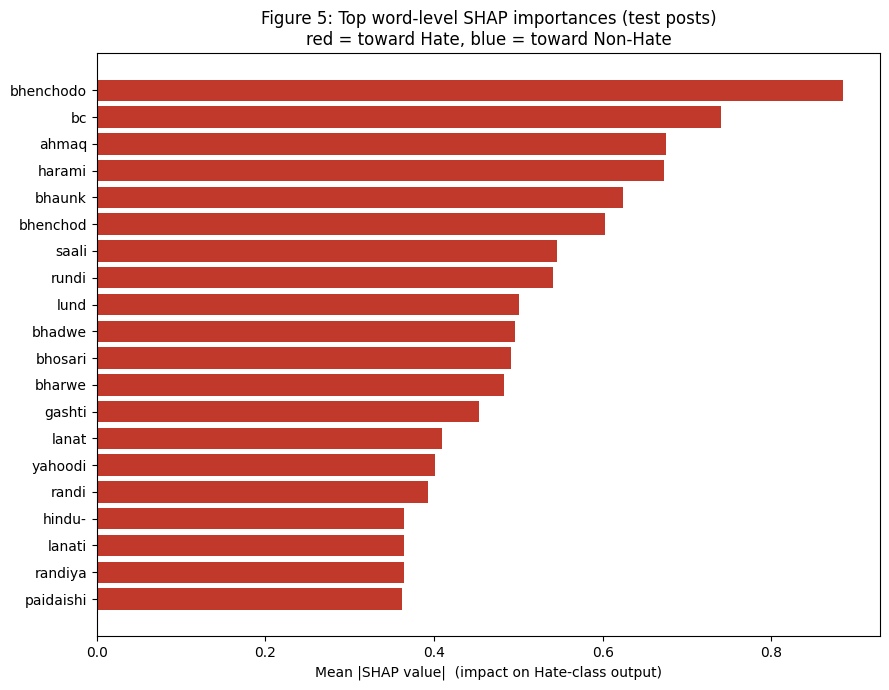


word              mean|SHAP|   mean SHAP   count
bhenchodo             0.8847      0.8847       2
bc                    0.7407      0.7407      10
ahmaq                 0.6747      0.6747       2
harami                0.6727      0.6727       3
bhaunk                0.6240      0.6240       4
bhenchod              0.6031      0.6031       7
saali                 0.5462      0.5462       2
rundi                 0.5406      0.5406       2
lund                  0.5012      0.5012       2
bhadwe                0.4961      0.4961       2
bhosari               0.4910      0.4910       2
bharwe                0.4833      0.4833       4
gashti                0.4528      0.4528       2
lanat                 0.4094      0.4094       3
yahoodi               0.4013      0.4013       9
randi                 0.3926      0.3926      10
hindu-                0.3640      0.3640       2
lanati                0.3639      0.3639       2
randiya               0.3638      0.3638       2
paidaishi          

In [26]:
# =====================================================================
#  WORD-LEVEL SHAP (one cell) — with empty-post filter + padding fix
# =====================================================================
import os, re, random, numpy as np, torch, matplotlib.pyplot as plt, shap
from collections import defaultdict
os.makedirs("shap_explanations", exist_ok=True)
HATE = 0

# --- prediction fn: pads short inputs to >=5 tokens so the kernel-4 CNN never fails ---
def predict_proba_for_shap(texts, batch_size=16, min_len=5):
    all_probs = []; model.eval()
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tokenizer(list(texts[i:i+batch_size]), padding=True, truncation=True,
                            max_length=128, return_tensors="pt")
            input_ids, attention_mask = enc["input_ids"], enc["attention_mask"]
            if input_ids.size(1) < min_len:
                pad_n = min_len - input_ids.size(1)
                input_ids = torch.cat([input_ids, torch.full((input_ids.size(0), pad_n),
                              tokenizer.pad_token_id, dtype=input_ids.dtype)], dim=1)
                attention_mask = torch.cat([attention_mask, torch.zeros((attention_mask.size(0), pad_n),
                              dtype=attention_mask.dtype)], dim=1)
            outputs = model(input_ids.to(DEVICE), attention_mask.to(DEVICE))
            all_probs.append(torch.softmax(outputs, dim=1).cpu().numpy())
    return np.vstack(all_probs)

# --- pick posts, then DROP any with fewer than 2 real words (fixes the SHAP crash) ---
_min_words = 2
def _ok(t): return isinstance(t, str) and len(re.findall(r"\w+", t)) >= _min_words
try:
    texts_to_explain = [t for t in texts_to_explain if _ok(t)]   # filter existing selection
except NameError:
    random.seed(42)
    _h = [t for t in df_test[df_test.label == 0].text.tolist() if _ok(t)]
    _n = [t for t in df_test[df_test.label == 1].text.tolist() if _ok(t)]
    texts_to_explain = random.sample(_h, 100) + random.sample(_n, 100)   # 200 balanced
    random.shuffle(texts_to_explain)
print("Explaining", len(texts_to_explain), "posts (word-level SHAP) — a few minutes...")

# --- WORD-LEVEL masker + explainer ---
masker = shap.maskers.Text(r"\W+", mask_token="[MASK]")
explainer = shap.Explainer(lambda x: predict_proba_for_shap(list(x)),
                           masker, output_names=["hate", "non-hate"])
shap_values = explainer(texts_to_explain)

# --- aggregate SHAP per word ---
agg = defaultdict(list)
for i in range(len(shap_values)):
    sv = shap_values[i]
    for tok, v in zip(sv.data, sv.values[:, HATE]):
        t = str(tok).strip().lower()
        if t and any(ch.isalpha() for ch in t):
            agg[t].append(float(v))

rows = [(t, np.mean(np.abs(v)), np.mean(v), len(v)) for t, v in agg.items() if len(v) >= 2]
rows.sort(key=lambda r: r[1], reverse=True)
top = rows[:20]
shap_top_words = {r[0] for r in top}

# --- plot (Figure 5) ---
tk=[r[0] for r in top][::-1]; imp=[r[1] for r in top][::-1]; sgn=[r[2] for r in top][::-1]
plt.figure(figsize=(9, 7))
plt.barh(range(len(top)), imp, color=["#C0392B" if s > 0 else "#2E86C1" for s in sgn])
plt.yticks(range(len(top)), tk)
plt.xlabel("Mean |SHAP value|  (impact on Hate-class output)")
plt.title("Figure 5: Top word-level SHAP importances (test posts)\nred = toward Hate, blue = toward Non-Hate")
plt.tight_layout(); plt.savefig("shap_explanations/shap_summary_class_hate.png", dpi=200); plt.show()

print(f"\n{'word':<16}{'mean|SHAP|':>12}{'mean SHAP':>12}{'count':>8}")
for t, a, s, c in top:
    print(f"{t:<16}{a:>12.4f}{s:>12.4f}{c:>8d}")
print("\nSHAP top words:", sorted(shap_top_words))

**Integrated Gradients (run AFTER the SHAP cell)**

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 18.5 MB/s eta 0:00:00


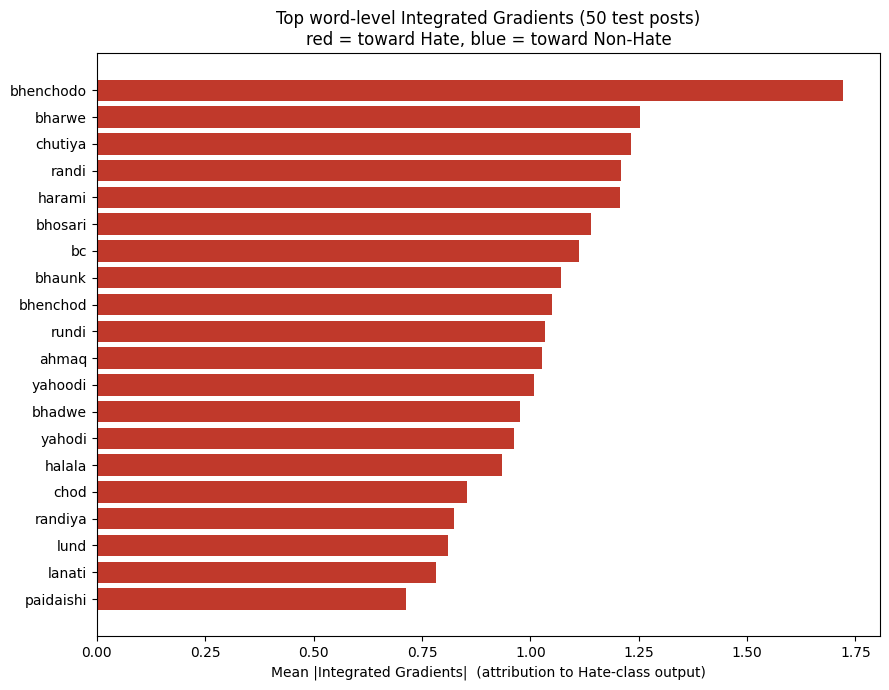

IG top words: ['ahmaq', 'bc', 'bhadwe', 'bharwe', 'bhaunk', 'bhenchod', 'bhenchodo', 'bhosari', 'chod', 'chutiya', 'halala', 'harami', 'lanati', 'lund', 'paidaishi', 'randi', 'randiya', 'rundi', 'yahodi', 'yahoodi']


In [27]:
!pip install captum
import numpy as np, torch, matplotlib.pyplot as plt, os
from collections import defaultdict
from captum.attr import LayerIntegratedGradients
os.makedirs("ig_explanations", exist_ok=True)
HATE = 0; model.eval()
cls_id, sep_id, pad_id = tokenizer.cls_token_id, tokenizer.sep_token_id, tokenizer.pad_token_id

def _forward(inp_ids, attn): return torch.softmax(model(inp_ids, attn), dim=1)
lig = LayerIntegratedGradients(_forward, model.bert.embeddings.word_embeddings)

def ig_words(text, target=HATE, n_steps=50):
    enc = tokenizer(text, truncation=True, max_length=128, return_tensors="pt",
                    return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")[0].tolist()
    ids  = enc["input_ids"].to(DEVICE); mask = enc["attention_mask"].to(DEVICE)
    base = ids.clone(); keep = (ids==cls_id)|(ids==sep_id); base[~keep] = pad_id
    att  = lig.attribute(ids, baselines=base, additional_forward_args=(mask,),
                         target=target, n_steps=n_steps)
    att  = att.sum(-1).squeeze(0)
    att  = (att / (torch.norm(att) + 1e-12)).detach().cpu().numpy()
    wid  = enc.word_ids(0)                              # which word each sub-token belongs to
    wsum = defaultdict(float); span = {}
    for k, (w, (s, e)) in enumerate(zip(wid, offsets)):
        if w is None: continue                          # skip [CLS]/[SEP]
        wsum[w] += float(att[k])
        if w not in span: span[w] = [s, e]
        else: span[w][1] = e
    order = sorted(wsum)
    words = [text[span[w][0]:span[w][1]] for w in order]
    vals  = [wsum[w] for w in order]
    return words, vals

agg = defaultdict(list)
for text in texts_to_explain:
    ws, vs = ig_words(text)
    for w, v in zip(ws, vs):
        t = w.strip().lower()
        if t and any(ch.isalpha() for ch in t):
            agg[t].append(v)

rows = [(t, np.mean(np.abs(v)), np.mean(v), len(v)) for t, v in agg.items() if len(v) >= 2]
rows.sort(key=lambda r: r[1], reverse=True)
top = rows[:20]
ig_top_words = {r[0] for r in top}                      # <-- saved for the overlap check

tk=[r[0] for r in top][::-1]; imp=[r[1] for r in top][::-1]; sgn=[r[2] for r in top][::-1]
plt.figure(figsize=(9,7))
plt.barh(range(len(top)), imp, color=["#C0392B" if s>0 else "#2E86C1" for s in sgn])
plt.yticks(range(len(top)), tk)
plt.xlabel("Mean |Integrated Gradients|  (attribution to Hate-class output)")
plt.title("Top word-level Integrated Gradients (50 test posts)\nred = toward Hate, blue = toward Non-Hate")
plt.tight_layout(); plt.savefig("ig_explanations/ig_top_words.png", dpi=200); plt.show()
print("IG top words:", sorted(ig_top_words))

**Attention-Visualization**

[transformers] `sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Rebuilt BERT with eager attention so attention weights are available.


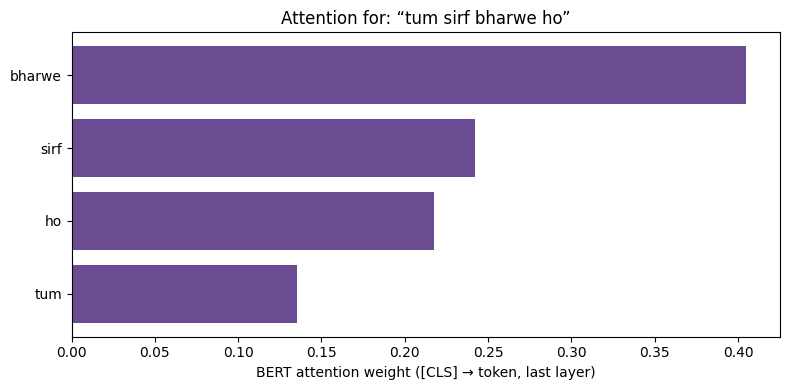

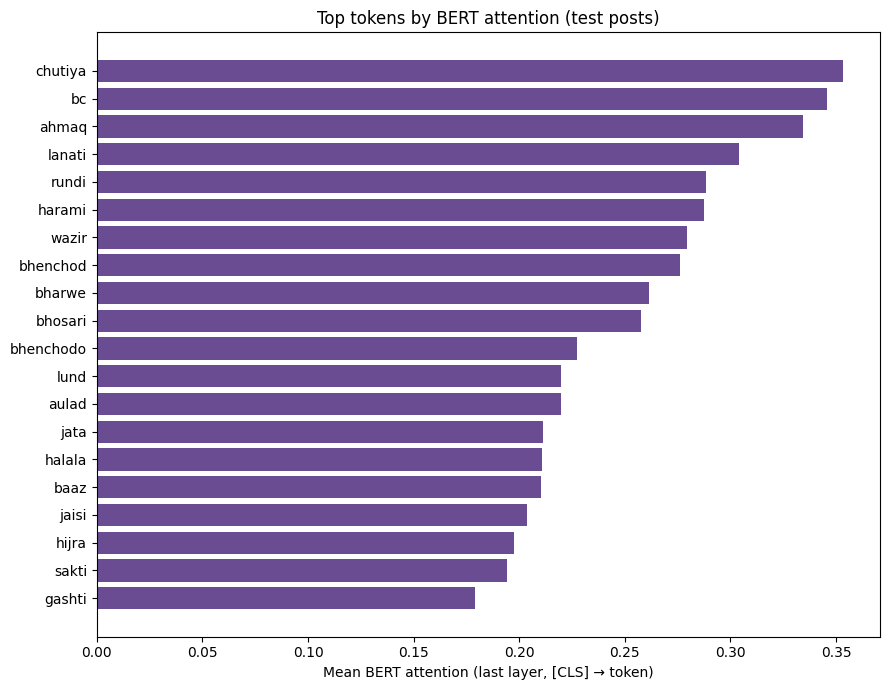

Saved attention plots to attention_explanations/


In [28]:
# === Attention Visualization (run after the LIME / SHAP / IG cells) ===
import torch, numpy as np, matplotlib.pyplot as plt, os
from collections import defaultdict
from transformers import AutoModel
os.makedirs("attention_explanations", exist_ok=True)
dev = globals().get('DEVICE', globals().get('device'))
HATE = 0
model.eval()

# --- Build an encoder that ACTUALLY returns attention weights ---
# Modern transformers defaults to SDPA/flash attention, which returns an EMPTY
# attentions tuple even with output_attentions=True -> "tuple index out of range".
# Test model.bert; if attentions come back empty, rebuild with eager + trained weights.
def _returns_attn(enc):
    with torch.no_grad():
        o = enc(input_ids=torch.tensor([[101, 102]]).to(dev),
                attention_mask=torch.tensor([[1, 1]]).to(dev),
                output_attentions=True)
    return o.attentions is not None and len(o.attentions) > 0

if _returns_attn(model.bert):
    bert_for_attn = model.bert
else:
    _name = getattr(model.bert.config, "_name_or_path", "bert-base-multilingual-cased")
    bert_for_attn = AutoModel.from_pretrained(_name, attn_implementation="eager").to(dev)
    bert_for_attn.load_state_dict(model.bert.state_dict())   # keep your fine-tuned weights
    bert_for_attn.eval()
    print("Rebuilt BERT with eager attention so attention weights are available.")

# per-word attention from BERT's last layer ([CLS] -> token, averaged over heads), merged to words
def word_attention(text, layer=-1):
    enc = tokenizer(text, truncation=True, max_length=128, return_tensors="pt", return_offsets_mapping=True)
    offsets = enc.pop("offset_mapping")[0].tolist()
    ids, mask = enc["input_ids"].to(dev), enc["attention_mask"].to(dev)
    with torch.no_grad():
        out = bert_for_attn(input_ids=ids, attention_mask=mask, output_attentions=True)
    att = out.attentions[layer][0].mean(0)          # (seq, seq), averaged over heads
    cls = att[0].cpu().numpy()                        # attention from [CLS] to each token
    wid = enc.word_ids(0)
    agg, span = defaultdict(float), {}
    for k, (w, (s, e)) in enumerate(zip(wid, offsets)):
        if w is None: continue                        # skip [CLS]/[SEP]
        agg[w] += float(cls[k]); span.setdefault(w, [s, e])[1] = e
    words = [text[span[w][0]:span[w][1]] for w in sorted(agg)]
    vals  = np.array([agg[w] for w in sorted(agg)], dtype=float)
    if vals.sum() > 0: vals = vals / vals.sum()       # normalise to sum 1
    return words, vals

# --- (A) attention for one example post ---
example = "tum sirf bharwe ho"
w, v = word_attention(example)
order = np.argsort(v)
plt.figure(figsize=(8, 4))
plt.barh(range(len(w)), v[order], color="#6A4C93")
plt.yticks(range(len(w)), [w[i] for i in order])
plt.xlabel("BERT attention weight ([CLS] → token, last layer)")
plt.title(f"Attention for: “{example}”")
plt.tight_layout(); plt.savefig("attention_explanations/attention_example.png", dpi=200); plt.show()

# --- (B) global: top tokens by average attention over the same posts used for SHAP/IG ---
try:
    texts = texts_to_explain
except NameError:
    import random; random.seed(42)
    _h = df_test[df_test.label==0].text.tolist(); _n = df_test[df_test.label==1].text.tolist()
    texts = random.sample(_h,25)+random.sample(_n,25)

g = defaultdict(list)
for t in texts:
    ws, vs = word_attention(t)
    for word, val in zip(ws, vs):
        tok = word.strip().lower()
        if tok and any(c.isalpha() for c in tok): g[tok].append(val)
rows = sorted(((k, np.mean(v), len(v)) for k,v in g.items() if len(v)>=2), key=lambda r:r[1], reverse=True)[:20]
labels=[r[0] for r in rows][::-1]; imp=[r[1] for r in rows][::-1]
plt.figure(figsize=(9,7))
plt.barh(range(len(rows)), imp, color="#6A4C93")
plt.yticks(range(len(rows)), labels)
plt.xlabel("Mean BERT attention (last layer, [CLS] → token)")
plt.title("Top tokens by BERT attention (test posts)")
plt.tight_layout(); plt.savefig("attention_explanations/attention_top_tokens.png", dpi=200); plt.show()
print("Saved attention plots to attention_explanations/")

In [29]:
overlap = ig_top_words & shap_top_words
print(f"SHAP vs IG word-level overlap: {len(overlap)}/20")
print("shared words:", sorted(overlap))

SHAP vs IG word-level overlap: 16/20
shared words: ['ahmaq', 'bc', 'bhadwe', 'bharwe', 'bhaunk', 'bhenchod', 'bhenchodo', 'bhosari', 'harami', 'lanati', 'lund', 'paidaishi', 'randi', 'randiya', 'rundi', 'yahoodi']


In [30]:
# =============================
#  Faithfulness evaluation: Comprehensiveness + Sufficiency (ERASER-style)
#  Run AFTER the SHAP / IG cells.
# =============================
import numpy as np, torch, math, random
random.seed(42); np.random.seed(42)
model.eval()

@torch.no_grad()
def _probs(texts, batch_size=32):
    out = []
    for i in range(0, len(texts), batch_size):
        b = list(texts[i:i+batch_size])
        if not b: continue
        enc = tokenizer(b, padding=True, truncation=True, max_length=128, return_tensors="pt")
        ids = enc["input_ids"].to(DEVICE); m = enc["attention_mask"].to(DEVICE)
        out.append(torch.softmax(model(ids, m), dim=1).cpu().numpy())
    return np.vstack(out) if out else np.zeros((0, 2))

def _occlusion_rank(words, target):
    # rank words by how much removing each one lowers the target-class probability
    base = _probs([" ".join(words)])[0, target]
    variants = [" ".join(words[:i] + words[i+1:]) for i in range(len(words))]
    p = _probs(variants)[:, target]
    return list(np.argsort(base - p)[::-1])      # most important word first

FRACS = [0.1, 0.2, 0.3, 0.4, 0.5]
def _faith_one(text, target):
    words = text.split(); n = len(words)
    if n < 3: return None
    order = _occlusion_rank(words, target)
    rand = order[:]; random.shuffle(rand)
    variants = [text]                            # [0] = full text (baseline)
    for f in FRACS:
        k = max(1, math.ceil(f * n))
        top = set(order[:k]); rk = set(rand[:k])
        variants.append(" ".join(w for i, w in enumerate(words) if i not in top))  # remove top-k
        variants.append(" ".join(w for i, w in enumerate(words) if i in top))      # keep only top-k
        variants.append(" ".join(w for i, w in enumerate(words) if i not in rk))   # remove random-k
    p = _probs(variants)[:, target]; base = p[0]
    comp, suff, compr = [], [], []; j = 1
    for _ in FRACS:
        comp.append(base - p[j]); suff.append(base - p[j+1]); compr.append(base - p[j+2]); j += 3
    return np.mean(comp), np.mean(suff), np.mean(compr)

# evaluate on the same posts used for SHAP/IG
try:
    eval_texts = texts_to_explain
except NameError:
    _h = df_test[df_test.label == 0].text.tolist(); _n = df_test[df_test.label == 1].text.tolist()
    eval_texts = random.sample(_h, 25) + random.sample(_n, 25)

C, S, R = [], [], []
for t in eval_texts:
    pred = int(np.argmax(_probs([t])[0]))        # explain the model's own prediction
    r = _faith_one(t, pred)
    if r: C.append(r[0]); S.append(r[1]); R.append(r[2])

print(f"Posts evaluated: {len(C)}")
print(f"Comprehensiveness (higher = better): {np.mean(C):.4f}")
print(f"Sufficiency       (lower  = better): {np.mean(S):.4f}")
print(f"Random-removal baseline            : {np.mean(R):.4f}")
print(f"--> explanations beat random by    : {np.mean(C) - np.mean(R):+.4f}")

Posts evaluated: 197
Comprehensiveness (higher = better): 0.4195
Sufficiency       (lower  = better): -0.0281
Random-removal baseline            : 0.0960
--> explanations beat random by    : +0.3235


In [31]:
!pip -q install gradio
import gradio as gr, torch, torch.nn.functional as F
dev = globals().get('DEVICE', globals().get('device'))

def detect(text):
    if not text.strip():
        return {"Hate (0)": 0.0, "Non-Hate (1)": 0.0}
    model.eval()
    enc = tokenizer([text], padding=True, truncation=True, max_length=128, return_tensors="pt")
    ids, mask = enc["input_ids"], enc["attention_mask"]
    if ids.size(1) < 5:                                   # pad short inputs for the kernel-4 CNN
        pad = 5 - ids.size(1)
        ids  = torch.cat([ids,  torch.full((1, pad), tokenizer.pad_token_id, dtype=ids.dtype)], 1)
        mask = torch.cat([mask, torch.zeros((1, pad), dtype=mask.dtype)], 1)
    with torch.no_grad():
        p = F.softmax(model(ids.to(dev), mask.to(dev)), dim=1)[0].cpu().numpy()
    return {"Hate (0)": float(p[0]), "Non-Hate (1)": float(p[1])}

demo = gr.Interface(
    fn=detect,
    inputs=gr.Textbox(lines=3, placeholder="Type a Roman Urdu sentence…", label="Enter text"),
    outputs=gr.Label(num_top_classes=2, label="Prediction"),
    title="🛡️ Roman Urdu Hate-Speech Detector",
    description="BERT + CNN-Gram model. Type a sentence and it predicts Hate vs Non-Hate with confidence.",
    examples=[["tum sirf bharwe ho"],
              ["Allah apko khush rakhe"],
              ["yeh banda bohat acha insaan hai"]],
    theme="soft",
)
demo.launch(share=True)

/usr/local/lib/python3.13/dist-packages/gradio/interface.py:171: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  super().__init__(


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://3770a1fe3668b2b668.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


In [32]:
import ipywidgets as widgets
from IPython.display import display
box = widgets.Textarea(placeholder="Type a sentence…", layout=widgets.Layout(width="70%", height="70px"))
btn = widgets.Button(description="Detect", button_style="primary")
out = widgets.Output()
def on_click(_):
    with out:
        out.clear_output()
        r = detect(box.value)   # uses the detect() function above
        print(f"Hate: {r['Hate (0)']:.1%}  |  Non-Hate: {r['Non-Hate (1)']:.1%}")
        print("→", "HATE" if r['Hate (0)'] >= r['Non-Hate (1)'] else "NON-HATE")
btn.on_click(on_click)
display(box, btn, out)

Textarea(value='', layout=Layout(height='70px', width='70%'), placeholder='Type a sentence…')

Button(button_style='primary', description='Detect', style=ButtonStyle())

Output()

In [33]:
model.load_state_dict(torch.load(MODEL_PATH, map_location=DEVICE))

<All keys matched successfully>

## Extended evaluation (added October 2026)

These cells **measure** the results reported in the paper; nothing in them is hard-coded. Report whatever numbers they print.

| Cell | What it produces |
|---|---|
| E1 | Config, data reload (raw, un-augmented), shared helpers |
| E2 | Re-scores the saved BERT+CNN-Gram checkpoint on the test set (all metrics incl. FNR/FPR) |
| E3–E6 | Baselines **re-trained here** under the same split/augmentation: TF-IDF+LR, mBERT fine-tuned, XLM-R+CNN-Gram, FastText+CNN-Gram |
| E7 | Comparison table (`results_table.csv`) |
| E8 | Significance: McNemar exact test + paired bootstrap 95% CI of macro-F1 difference vs each baseline |
| E9 | 5-fold stratified cross-validation of BERT+CNN-Gram (mean ± std) |
| E10 | Error analysis by fine-grained category (RUHSOLD Task 2) and by keyword-defined domain (political / religious / other) |
| E11 | Decision-threshold sweep: FNR vs FPR trade-off |
| E12 | Embedding-space separation (cosine similarity, silhouette, t-SNE): pre-trained mBERT vs fine-tuned model |

Every result is written to `EXT_DIR` on Google Drive as soon as it is computed, so if Colab disconnects, re-run E1 and continue: finished steps are loaded instead of re-run.
**Runtime on a T4:** roughly 2–3 hours in total (E9 is the longest). Results from published papers (e.g. Rizwan et al., 2020) are **not** computed here; cite them separately as "reported by".

In [34]:
# E1 — configuration, raw data, helpers
!pip -q install gensim
import os, re, json, random, numpy as np, pandas as pd, torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModel
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, matthews_corrcoef, cohen_kappa_score, confusion_matrix)

EXT_DIR   = "/content/drive/MyDrive/thesis_extended_results"   # results survive a disconnect
CKPT_DIR  = "/content/ext_ckpt"                                  # temporary model weights (local, large)
os.makedirs(EXT_DIR, exist_ok=True); os.makedirs(CKPT_DIR, exist_ok=True)
DEVICE    = torch.device("cuda" if torch.cuda.is_available() else "cpu")
SEED, MAX_LEN, BATCH = 42, 128, 16
EXT_EPOCHS, EXT_PATIENCE = 15, 3       # max epochs / early-stopping patience for models trained here
MBERT, XLMR = "bert-base-multilingual-cased", "xlm-roberta-base"
DATA_BASE = "https://raw.githubusercontent.com/haroonshakeel/roman_urdu_hate_speech/main/"
HATE = 0                                # label 0 = Hate/Abusive (positive class for FNR/FPR), 1 = Normal

def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def load_raw(name):
    d = pd.read_csv(DATA_BASE + name, sep="\t", header=None, names=["text", "label"], encoding="utf-8")
    d["text"] = d["text"].astype(str); d["label"] = d["label"].astype(int)
    return d

raw_train, raw_val, raw_test = load_raw("task_1_train.tsv"), load_raw("task_1_validation.tsv"), load_raw("task_1_test.tsv")
y_test = raw_test["label"].values
print("train/val/test:", len(raw_train), len(raw_val), len(raw_test))

_EN = ['bro', 'yaar', 'bhai', 'lol', 'ok', 'please', 'stop']
def augment_df(df, frac=0.3, seed=SEED):
    """Same augmentation as the main training (cell 10), seeded, applied to training data only."""
    rng = random.Random(seed)
    def aug(t):
        w = str(t).split()
        if w and rng.random() < 0.5: w.insert(rng.randint(0, len(w)), rng.choice(_EN))
        if len(w) > 1 and rng.random() < 0.5:
            i, j = rng.sample(range(len(w)), 2); w[i], w[j] = w[j], w[i]
        return " ".join(w)
    a = df.sample(frac=frac, random_state=seed).copy(); a["text"] = a["text"].apply(aug)
    return pd.concat([df, a], ignore_index=True)

aug_train = augment_df(raw_train)

def metrics(y_true, p_hate, thr=0.5):
    """All metrics with Hate (label 0) as the positive class for FNR/FPR."""
    y_true = np.asarray(y_true); p_hate = np.asarray(p_hate)
    pred = np.where(p_hate >= thr, HATE, 1)
    p, r, f1, _ = precision_recall_fscore_support(y_true, pred, average="macro", zero_division=0)
    is_h, pred_h = (y_true == HATE), (pred == HATE)
    return {"accuracy": accuracy_score(y_true, pred), "macro_precision": p, "macro_recall": r, "macro_f1": f1,
            "roc_auc": roc_auc_score(is_h, p_hate), "pr_auc": average_precision_score(is_h, p_hate),
            "mcc": matthews_corrcoef(y_true, pred), "kappa_model_vs_gold": cohen_kappa_score(y_true, pred),
            "fnr": float((is_h & ~pred_h).sum() / max(is_h.sum(), 1)),      # hate speech missed
            "fpr": float((~is_h & pred_h).sum() / max((~is_h).sum(), 1))}   # normal posts flagged

def save_json(name, obj):
    with open(f"{EXT_DIR}/{name}.json", "w") as f: json.dump(obj, f, indent=2, default=float)
def load_json(name):
    p = f"{EXT_DIR}/{name}.json"
    return json.load(open(p)) if os.path.exists(p) else None

def cached_probs(tag, fn):
    """Run fn() -> p_hate on the test set once; afterwards load it from Drive."""
    p = f"{EXT_DIR}/probs_{tag}.npy"
    if os.path.exists(p):
        print(f"[{tag}] loaded cached test probabilities"); return np.load(p)
    out = np.asarray(fn()); np.save(p, out); return out

# ---------- transformer training / prediction (same recipe as the main model) ----------
def make_loader(df, tok, shuffle):
    ds = RomanUrduDataset(df.reset_index(drop=True), tok, MAX_LEN)
    g = torch.Generator(); g.manual_seed(SEED)
    return DataLoader(ds, batch_size=BATCH, shuffle=shuffle, generator=g if shuffle else None)

def param_groups(model, base_lr=2e-5, head_lr=2e-4, decay=0.95):
    """Layer-wise learning-rate decay, as in cell 13."""
    n = model.bert.config.num_hidden_layers; groups = []
    for name, prm in model.named_parameters():
        if not prm.requires_grad: continue
        if "bert.encoder.layer." in name:
            li = int(name.split("bert.encoder.layer.")[1].split(".")[0]); lr = base_lr * decay ** (n - 1 - li)
        elif name.startswith("bert."): lr = base_lr * decay ** n
        else: lr = head_lr
        groups.append({"params": [prm], "lr": lr})
    return groups

def _loss_on(model, loader, crit):
    model.eval(); tot = 0.0
    with torch.no_grad():
        for b in loader:
            out = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE))
            tot += crit(out, b["labels"].to(DEVICE)).item()
    return tot / len(loader)

def train_transformer(model, tok, tr_df, va_df, tag):
    set_seed(); model.to(DEVICE)
    opt = torch.optim.Adam(param_groups(model)); crit = nn.CrossEntropyLoss(label_smoothing=0.1)
    use_amp = DEVICE.type == "cuda"; scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    trl, val = make_loader(tr_df, tok, True), make_loader(va_df, tok, False)
    best, bad, path = float("inf"), 0, f"{CKPT_DIR}/{tag}.pth"
    for ep in range(EXT_EPOCHS):
        model.train()
        for b in trl:
            opt.zero_grad()
            with torch.autocast(device_type=DEVICE.type, enabled=use_amp):
                loss = crit(model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)), b["labels"].to(DEVICE))
            scaler.scale(loss).backward(); scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0); scaler.step(opt); scaler.update()
        vl = _loss_on(model, val, crit); print(f"[{tag}] epoch {ep+1}  val_loss {vl:.4f}")
        if vl < best: best, bad = vl, 0; torch.save(model.state_dict(), path)
        else:
            bad += 1
            if bad >= EXT_PATIENCE: print(f"[{tag}] early stop"); break
    model.load_state_dict(torch.load(path, map_location=DEVICE)); os.remove(path)
    return model

def predict_transformer(model, tok, df):
    model.to(DEVICE).eval(); ps = []
    with torch.no_grad():
        for b in make_loader(df, tok, False):
            out = model(b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE))
            ps.extend(F.softmax(out.float(), dim=1)[:, HATE].cpu().numpy())
    return np.array(ps)

def free(*objs):
    for o in objs: del o
    if torch.cuda.is_available(): torch.cuda.empty_cache()

mbert_tok = AutoTokenizer.from_pretrained(MBERT)
RESULTS = load_json("results") or {}
print("device:", DEVICE, "| results already on Drive:", list(RESULTS))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 19.1 MB/s eta 0:00:00
train/val/test: 7209 801 2003
device: cuda | results already on Drive: ['BERT+CNN-Gram (ours)', 'TF-IDF + Logistic Regression']


In [35]:
# E2 — re-score the saved BERT+CNN-Gram checkpoint (the model used for LIME/SHAP/IG)
CKPT = MODEL_PATH if os.path.exists(MODEL_PATH) else "best_model.pth"
def _ours():
    m = BERT_CNN_Gram(); m.load_state_dict(torch.load(CKPT, map_location=DEVICE))
    p = predict_transformer(m, mbert_tok, raw_test); free(m); return p
p_ours = cached_probs("ours", _ours)
RESULTS["BERT+CNN-Gram (ours)"] = metrics(y_test, p_ours); save_json("results", RESULTS)
pd.Series(RESULTS["BERT+CNN-Gram (ours)"]).round(4)

[ours] loaded cached test probabilities


,0
accuracy,0.9026
macro_precision,0.9020
macro_recall,0.9025
macro_f1,0.9022
roc_auc,0.9616
pr_auc,0.9633
mcc,0.8045
kappa_model_vs_gold,0.8045
fnr,0.0997
fpr,0.0953


In [36]:
# E3 — baseline: TF-IDF (word 1-2 grams + char 2-5 grams) + logistic regression; C tuned on validation
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import make_union
from sklearn.linear_model import LogisticRegression
def _tfidf():
    def vec(): return make_union(TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True),
                                 TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True))
    best = None
    for C in [0.1, 0.3, 1, 3, 10]:
        v = vec(); Xtr = v.fit_transform(aug_train.text)
        clf = LogisticRegression(C=C, max_iter=3000).fit(Xtr, aug_train.label)
        f1 = precision_recall_fscore_support(raw_val.label, clf.predict(v.transform(raw_val.text)), average="macro")[2]
        if best is None or f1 > best[0]: best = (f1, C, v, clf)
    f1, C, v, clf = best; print(f"best C={C} (val macro-F1 {f1:.4f})")
    return clf.predict_proba(v.transform(raw_test.text))[:, list(clf.classes_).index(HATE)]
p_tfidf = cached_probs("tfidf_lr", _tfidf)
RESULTS["TF-IDF + Logistic Regression"] = metrics(y_test, p_tfidf); save_json("results", RESULTS)
pd.Series(RESULTS["TF-IDF + Logistic Regression"]).round(4)

[tfidf_lr] loaded cached test probabilities


,0
accuracy,0.8952
macro_precision,0.8954
macro_recall,0.8938
macro_f1,0.8945
roc_auc,0.9594
pr_auc,0.9589
mcc,0.7892
kappa_model_vs_gold,0.7890
fnr,0.1254
fpr,0.0869


In [37]:
# E4 — baseline: mBERT fine-tuned with a linear head on [CLS] (no CNN-Gram)
class BERTClassifier(nn.Module):
    def __init__(self, name=MBERT, num_classes=2):
        super().__init__(); self.bert = AutoModel.from_pretrained(name)
        self.dropout = nn.Dropout(0.3); self.fc = nn.Linear(self.bert.config.hidden_size, num_classes)
    def forward(self, input_ids, attention_mask):
        h = self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0]
        return self.fc(self.dropout(h))
def _mbert():
    set_seed(); m = train_transformer(BERTClassifier(), mbert_tok, aug_train, raw_val, "mbert_ft")
    p = predict_transformer(m, mbert_tok, raw_test); free(m); return p
p_mbert = cached_probs("mbert_ft", _mbert)
RESULTS["mBERT fine-tuned"] = metrics(y_test, p_mbert); save_json("results", RESULTS)
pd.Series(RESULTS["mBERT fine-tuned"]).round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[mbert_ft] epoch 1  val_loss 0.4075
[mbert_ft] epoch 2  val_loss 0.4783
[mbert_ft] epoch 3  val_loss 0.4353
[mbert_ft] epoch 4  val_loss 0.4767
[mbert_ft] early stop


,0
accuracy,0.8907
macro_precision,0.8900
macro_recall,0.8914
macro_f1,0.8904
roc_auc,0.9517
pr_auc,0.9547
mcc,0.7813
kappa_model_vs_gold,0.7808
fnr,0.0986
fpr,0.1187


In [38]:
# E5 — baseline: XLM-RoBERTa + CNN-Gram (same architecture and recipe, different encoder)
xlmr_tok = AutoTokenizer.from_pretrained(XLMR)
def _xlmr():
    set_seed(); m = train_transformer(BERT_CNN_Gram(bert_model_name=XLMR), xlmr_tok, aug_train, raw_val, "xlmr_cnn")
    p = predict_transformer(m, xlmr_tok, raw_test); free(m); return p
p_xlmr = cached_probs("xlmr_cnn", _xlmr)
RESULTS["XLM-R + CNN-Gram"] = metrics(y_test, p_xlmr); save_json("results", RESULTS)
pd.Series(RESULTS["XLM-R + CNN-Gram"]).round(4)

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] XLMRobertaModel LOAD REPORT from: xlm-roberta-base
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[xlmr_cnn] epoch 1  val_loss 0.4361
[xlmr_cnn] epoch 2  val_loss 0.3996
[xlmr_cnn] epoch 3  val_loss 0.3889
[xlmr_cnn] epoch 4  val_loss 0.3972
[xlmr_cnn] epoch 5  val_loss 0.4099
[xlmr_cnn] epoch 6  val_loss 0.4267
[xlmr_cnn] early stop


,0
accuracy,0.9076
macro_precision,0.9070
macro_recall,0.9085
macro_f1,0.9074
roc_auc,0.9511
pr_auc,0.9291
mcc,0.8154
kappa_model_vs_gold,0.8149
fnr,0.0793
fpr,0.1037


In [39]:
# E6 — baseline: FastText embeddings (trained on RUHSOLD train text) + CNN-Gram
from gensim.models import FastText
def wtok(t): return re.findall(r"\w+|[^\w\s]", str(t).lower())
class FT_CNN_Gram(nn.Module):
    def __init__(self, emb, num_filters=128, sizes=(1, 2, 3, 4)):
        super().__init__()
        self.emb = nn.Embedding.from_pretrained(torch.tensor(emb, dtype=torch.float), freeze=False, padding_idx=0)
        self.convs = nn.ModuleList([nn.Conv1d(emb.shape[1], num_filters, k) for k in sizes])
        self.bns = nn.ModuleList([nn.BatchNorm1d(num_filters) for _ in sizes])
        self.dropout = nn.Dropout(0.5); self.fc = nn.Linear(num_filters * len(sizes), 2)
    def forward(self, ids):
        x = self.emb(ids).permute(0, 2, 1)
        x = torch.cat([torch.relu(bn(c(x))).max(2)[0] for c, bn in zip(self.convs, self.bns)], 1)
        return self.fc(self.dropout(x))
def _fasttext():
    set_seed()
    ft = FastText(sentences=[wtok(t) for t in aug_train.text], vector_size=300, window=5, min_count=1,
                  epochs=10, seed=SEED, workers=1)
    vocab = {"<pad>": 0, "<unk>": 1}
    for d in (aug_train, raw_val, raw_test):            # token strings only (no labels); FastText builds OOV vectors from subwords
        for t in d.text:
            for w in wtok(t): vocab.setdefault(w, len(vocab))
    emb = np.zeros((len(vocab), 300), dtype=np.float32)
    for w, i in vocab.items():
        if i > 1: emb[i] = ft.wv[w]
    L = 64
    def enc(df):
        ids = [[vocab.get(w, 1) for w in wtok(t)][:L] for t in df.text]
        ids = [s + [0] * (L - len(s)) for s in ids]
        return torch.tensor(ids), torch.tensor(df.label.values)
    (Xtr, ytr), (Xva, yva), (Xte, _) = enc(aug_train), enc(raw_val), enc(raw_test)
    m = FT_CNN_Gram(emb).to(DEVICE); opt = torch.optim.Adam(m.parameters(), lr=1e-3); crit = nn.CrossEntropyLoss()
    g = torch.Generator(); g.manual_seed(SEED)
    best, bad, state = float("inf"), 0, None
    for ep in range(30):
        m.train()
        for idx in torch.randperm(len(Xtr), generator=g).split(64):
            opt.zero_grad(); loss = crit(m(Xtr[idx].to(DEVICE)), ytr[idx].to(DEVICE)); loss.backward(); opt.step()
        m.eval()
        with torch.no_grad(): vl = crit(m(Xva.to(DEVICE)), yva.to(DEVICE)).item()
        print(f"[fasttext_cnn] epoch {ep+1}  val_loss {vl:.4f}")
        if vl < best: best, bad, state = vl, 0, {k: v.detach().clone() for k, v in m.state_dict().items()}
        else:
            bad += 1
            if bad >= EXT_PATIENCE: break
    m.load_state_dict(state); m.eval()
    with torch.no_grad(): p = F.softmax(m(Xte.to(DEVICE)), 1)[:, HATE].cpu().numpy()
    free(m); return p
p_ft = cached_probs("fasttext_cnn", _fasttext)
RESULTS["FastText + CNN-Gram"] = metrics(y_test, p_ft); save_json("results", RESULTS)
pd.Series(RESULTS["FastText + CNN-Gram"]).round(4)

[fasttext_cnn] epoch 1  val_loss 0.4445
[fasttext_cnn] epoch 2  val_loss 0.3441
[fasttext_cnn] epoch 3  val_loss 0.3377
[fasttext_cnn] epoch 4  val_loss 0.2929
[fasttext_cnn] epoch 5  val_loss 0.3157
[fasttext_cnn] epoch 6  val_loss 0.3711
[fasttext_cnn] epoch 7  val_loss 0.3639


,0
accuracy,0.9011
macro_precision,0.9011
macro_recall,0.9001
macro_f1,0.9006
roc_auc,0.9574
pr_auc,0.9588
mcc,0.8013
kappa_model_vs_gold,0.8011
fnr,0.1147
fpr,0.0850


In [40]:
# E7 — comparison table (all models trained and evaluated in this notebook, same test set)
order = ["BERT+CNN-Gram (ours)", "mBERT fine-tuned", "XLM-R + CNN-Gram", "FastText + CNN-Gram", "TF-IDF + Logistic Regression"]
cols = ["accuracy", "macro_precision", "macro_recall", "macro_f1", "roc_auc", "pr_auc", "mcc", "fnr", "fpr"]
table = pd.DataFrame(RESULTS).T.reindex([o for o in order if o in RESULTS])[cols].astype(float).round(4)
table.to_csv(f"{EXT_DIR}/results_table.csv")
print(table.to_markdown())

|                              |   accuracy |   macro_precision |   macro_recall |   macro_f1 |   roc_auc |   pr_auc |    mcc |    fnr |    fpr |
|:-----------------------------|-----------:|------------------:|---------------:|-----------:|----------:|---------:|-------:|-------:|-------:|
| BERT+CNN-Gram (ours)         |     0.9026 |            0.902  |         0.9025 |     0.9022 |    0.9616 |   0.9633 | 0.8045 | 0.0997 | 0.0953 |
| mBERT fine-tuned             |     0.8907 |            0.89   |         0.8914 |     0.8904 |    0.9517 |   0.9547 | 0.7813 | 0.0986 | 0.1187 |
| XLM-R + CNN-Gram             |     0.9076 |            0.907  |         0.9085 |     0.9074 |    0.9511 |   0.9291 | 0.8154 | 0.0793 | 0.1037 |
| FastText + CNN-Gram          |     0.9011 |            0.9011 |         0.9001 |     0.9006 |    0.9574 |   0.9588 | 0.8013 | 0.1147 | 0.085  |
| TF-IDF + Logistic Regression |     0.8952 |            0.8954 |         0.8938 |     0.8945 |    0.9594 |   0.9589 | 0.789

In [41]:
# E8 — significance vs each re-trained baseline: McNemar exact test + paired bootstrap of macro-F1 difference
from scipy.stats import binomtest
PROBS = {"mBERT fine-tuned": p_mbert, "XLM-R + CNN-Gram": p_xlmr, "FastText + CNN-Gram": p_ft,
         "TF-IDF + Logistic Regression": p_tfidf}
pred = lambda p: np.where(p >= 0.5, HATE, 1)
def macro_f1(y, yhat): return precision_recall_fscore_support(y, yhat, average="macro", zero_division=0)[2]
rng = np.random.default_rng(SEED); B = 2000
boot_idx = [rng.integers(0, len(y_test), len(y_test)) for _ in range(B)]
SIG = {}
po = pred(p_ours); ok_o = po == y_test
for name, p in PROBS.items():
    pb = pred(p); ok_b = pb == y_test
    b, c = int((ok_o & ~ok_b).sum()), int((~ok_o & ok_b).sum())     # discordant pairs
    p_mc = binomtest(b, b + c, 0.5).pvalue if b + c else 1.0
    diffs = np.array([macro_f1(y_test[i], po[i]) - macro_f1(y_test[i], pb[i]) for i in boot_idx])
    SIG[name] = {"ours_right_baseline_wrong": b, "ours_wrong_baseline_right": c, "mcnemar_p": p_mc,
                 "macro_f1_diff": macro_f1(y_test, po) - macro_f1(y_test, pb),
                 "diff_ci95_low": float(np.percentile(diffs, 2.5)), "diff_ci95_high": float(np.percentile(diffs, 97.5))}
save_json("significance", SIG)
pd.DataFrame(SIG).T.round(4)

,ours_right_baseline_wrong,ours_wrong_baseline_right,mcnemar_p,macro_f1_diff,diff_ci95_low,diff_ci95_high
mBERT fine-tuned,81.0,57.0,0.0498,0.0119,-0.0002,0.0229
XLM-R + CNN-Gram,86.0,96.0,0.5048,-0.0052,-0.0183,0.0078
FastText + CNN-Gram,94.0,91.0,0.8831,0.0017,-0.0114,0.0151
TF-IDF + Logistic Regression,95.0,80.0,0.2899,0.0078,-0.0056,0.0206


In [42]:
# E9 — 5-fold stratified cross-validation of BERT+CNN-Gram on train+validation (8,010 posts)
# Per fold: 10% of the training folds is held out for early stopping; augmentation is applied to the
# training part only (after splitting), so augmented copies never leak into the evaluated fold.
from sklearn.model_selection import StratifiedKFold, train_test_split
pool = pd.concat([raw_train, raw_val], ignore_index=True)
CV = load_json("cv_folds") or {}
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
for k, (tr_i, te_i) in enumerate(skf.split(pool.text, pool.label)):
    if str(k) in CV: print(f"fold {k}: cached"); continue
    tr, te = pool.iloc[tr_i], pool.iloc[te_i]
    tr, va = train_test_split(tr, test_size=0.1, stratify=tr.label, random_state=SEED)
    set_seed(SEED + k)
    m = train_transformer(BERT_CNN_Gram(), mbert_tok, augment_df(tr, seed=SEED + k), va, f"cv{k}")
    CV[str(k)] = {"heldout_fold": metrics(te.label.values, predict_transformer(m, mbert_tok, te)),
                  "official_test": metrics(y_test, predict_transformer(m, mbert_tok, raw_test))}
    save_json("cv_folds", CV); free(m)
    print(f"fold {k}: held-out macro-F1 {CV[str(k)]['heldout_fold']['macro_f1']:.4f}")
summ = {}
for part in ["heldout_fold", "official_test"]:
    df = pd.DataFrame([CV[k][part] for k in sorted(CV)])
    summ[part] = {m: f"{df[m].mean():.4f} ± {df[m].std(ddof=1):.4f}" for m in ["accuracy", "macro_f1", "roc_auc", "mcc", "fnr", "fpr"]}
save_json("cv_summary", summ)
pd.DataFrame(summ)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[cv0] epoch 1  val_loss 0.4278
[cv0] epoch 2  val_loss 0.4181
[cv0] epoch 3  val_loss 0.4520
[cv0] epoch 4  val_loss 0.5529
[cv0] epoch 5  val_loss 0.4992
[cv0] early stop
fold 0: held-out macro-F1 0.8730


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


...

[cv3] epoch 1  val_loss 0.4043
[cv3] epoch 2  val_loss 0.3780
[cv3] epoch 3  val_loss 0.3795
[cv3] epoch 4  val_loss 0.4014
[cv3] epoch 5  val_loss 0.3888
[cv3] early stop
fold 3: held-out macro-F1 0.8564


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


[cv4] epoch 1  val_loss 0.4907
[cv4] epoch 2  val_loss 0.4078
[cv4] epoch 3  val_loss 0.4409
[cv4] epoch 4  val_loss 0.4600
[cv4] epoch 5  val_loss 0.4881
[cv4] early stop
fold 4: held-out macro-F1 0.8815


,heldout_fold,official_test
accuracy,0.8729 ± 0.0115,0.8841 ± 0.0083
macro_f1,0.8718 ± 0.0108,0.8834 ± 0.0078
roc_auc,0.9362 ± 0.0030,0.9497 ± 0.0060
mcc,0.7479 ± 0.0225,0.7698 ± 0.0130
fnr,0.1528 ± 0.0466,0.1245 ± 0.0420
fpr,0.1047 ± 0.0575,0.1084 ± 0.0509


In [43]:
# E10 — error analysis (a) by RUHSOLD fine-grained category, (b) by keyword-defined domain
# (a) Fine-grained labels come from the Task 2 files, matched to the Task 1 test set by exact text.
t2 = pd.concat([load_raw(f"task_2_{s}.tsv") for s in ["train", "validation", "test"]]).drop_duplicates("text")
FINE = {0: "Abusive/Offensive", 1: "Normal", 2: "Religious Hate", 3: "Sexism", 4: "Profane/Untargeted"}
ea = raw_test.assign(p_hate=p_ours, pred=np.where(p_ours >= 0.5, HATE, 1)).merge(
        t2.rename(columns={"label": "fine"})[["text", "fine"]], on="text", how="left")
print(f"test posts with a fine-grained label: {ea.fine.notna().sum()} / {len(ea)}")
cat = (ea.dropna(subset=["fine"]).assign(category=lambda d: d.fine.astype(int).map(FINE))
         .groupby("category").apply(lambda d: pd.Series({"n": len(d), "flagged_as_hate": (d.pred == HATE).mean()}),
                                    include_groups=False))
cat["meaning"] = np.where(cat.index == "Normal", "false positive rate", "detection rate (1 - FNR)")
print(cat.round(4))

# (b) Keyword domains — a HEURISTIC (RUHSOLD has no domain labels). Edit the lists if needed and report them in the paper.
DOMAINS = {
 "political": r"\b(?:pti|pmln|pml|ppp|imran|nawaz|niazi|zardari|bilawal|maryam|mariam|shahbaz|modi|bjp|congress|govt|government|hakumat|sarkar|vote|election|minister|wazir|army|fauj|patwari|youthia|siyasat|siasat)\b",
 "religious": r"\b(?:allah|islam|muslim|musalman|hindu|sikh|christian|isai|eesai|mandir|masjid|maulana|molvi|mullah|mulla|qadiani|ahmadi|shia|sunni|kafir|kaafir|deen|mazhab|quran|nabi)\b"}
low = ea.text.str.lower()
ea["domain"] = "other"
for d, rx in DOMAINS.items(): ea.loc[low.str.contains(rx, regex=True) & (ea.domain == "other"), "domain"] = d
def dom_stats(d):
    y, yh = d.label.values, d.pred.values; m = metrics(y, d.p_hate.values) if len(set(y)) > 1 else {}
    return pd.Series({"n": len(d), "n_hate": int((y == HATE).sum()),
                      "precision_hate": precision_recall_fscore_support(y, yh, labels=[HATE], zero_division=0)[0][0],
                      "fnr": m.get("fnr", np.nan), "fpr": m.get("fpr", np.nan), "macro_f1": m.get("macro_f1", np.nan)})
dom = ea.groupby("domain").apply(dom_stats, include_groups=False)
save_json("error_analysis", {"fine_grained": cat.reset_index().to_dict("records"), "domains": dom.reset_index().to_dict("records")})
dom.round(4)

test posts with a fine-grained label: 1842 / 2003
                        n  flagged_as_hate                   meaning
category                                                            
Abusive/Offensive   435.0           0.8736  detection rate (1 - FNR)
Normal              987.0           0.0922       false positive rate
Profane/Untargeted  120.0           0.9583  detection rate (1 - FNR)
Religious Hate      146.0           0.8836  detection rate (1 - FNR)
Sexism              154.0           0.9286  detection rate (1 - FNR)


,n,n_hate,precision_hate,fnr,fpr,macro_f1
domain,,,,,,
other,1763.0,807.0,0.9061,0.0917,0.0795,0.9143
political,122.0,84.0,0.8902,0.1310,0.2368,0.8116
religious,118.0,42.0,0.6667,0.1905,0.2237,0.7782


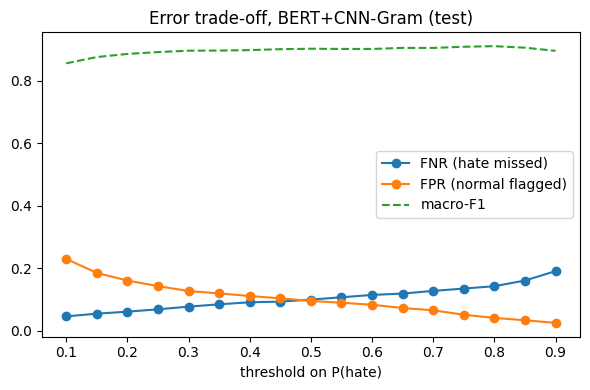

,threshold,fnr,fpr,macro_f1
0,0.10,0.0461,0.2299,0.8556
1,0.15,0.0547,0.1850,0.8757
2,0.20,0.0611,0.1607,0.8857
3,0.25,0.0686,0.1430,0.8916
4,0.30,0.0772,0.1271,0.8960
5,0.35,0.0847,0.1196,0.8965
6,0.40,0.0911,0.1112,0.8979
7,0.45,0.0932,0.1037,0.9008
8,0.50,0.0997,0.0953,0.9022
9,0.55,0.1072,0.0897,0.9017


In [44]:
# E11 — decision-threshold sweep: trade-off between missed hate speech (FNR) and false alarms (FPR)
thr = np.round(np.arange(0.10, 0.91, 0.05), 2)
sweep = pd.DataFrame([{"threshold": t, **{k: metrics(y_test, p_ours, t)[k] for k in ["fnr", "fpr", "macro_f1"]}} for t in thr])
sweep.to_csv(f"{EXT_DIR}/threshold_sweep.csv", index=False)
plt.figure(figsize=(6, 4))
plt.plot(sweep.threshold, sweep.fnr, marker="o", label="FNR (hate missed)")
plt.plot(sweep.threshold, sweep.fpr, marker="o", label="FPR (normal flagged)")
plt.plot(sweep.threshold, sweep.macro_f1, linestyle="--", label="macro-F1")
plt.xlabel("threshold on P(hate)"); plt.legend(); plt.title("Error trade-off, BERT+CNN-Gram (test)")
plt.tight_layout(); plt.savefig(f"{EXT_DIR}/threshold_sweep.png", dpi=150); plt.show()
sweep.round(4)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-multilingual-cased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


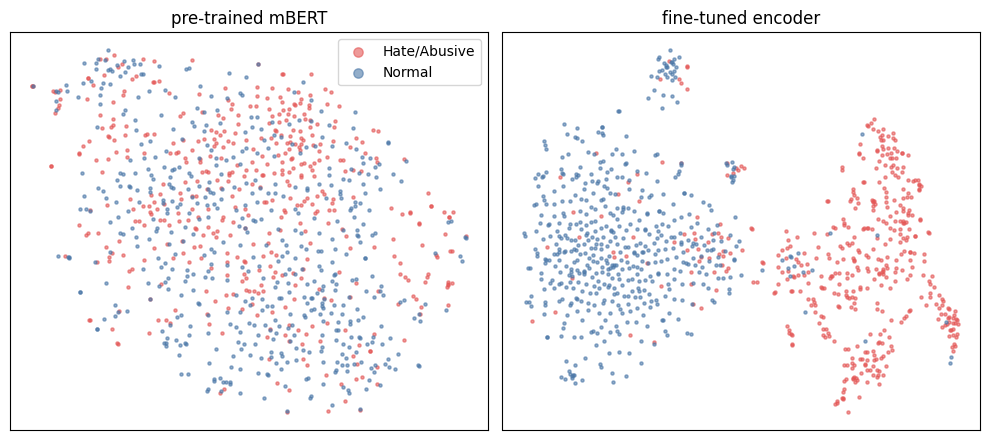

,pre-trained mBERT,fine-tuned (BERT+CNN-Gram encoder)
cos_hate_hate,0.6653,0.6782
cos_normal_normal,0.6443,0.8374
cos_hate_normal,0.6486,0.4372
silhouette_cosine,0.0157,0.5245


In [45]:
# E12 — embedding-space separation: pre-trained mBERT vs the fine-tuned model (mean-pooled encoder output)
from sklearn.metrics import silhouette_score
from sklearn.manifold import TSNE
def embed(encoder, df):
    encoder.to(DEVICE).eval(); out = []
    with torch.no_grad():
        for b in make_loader(df, mbert_tok, False):
            ids, am = b["input_ids"].to(DEVICE), b["attention_mask"].to(DEVICE)
            h = encoder(input_ids=ids, attention_mask=am).last_hidden_state; m = am.unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1)).cpu().numpy())
    e = np.concatenate(out); return e / np.linalg.norm(e, axis=1, keepdims=True)
def separation(e, y):
    S = e @ e.T; h, n = (y == HATE), (y != HATE); off = ~np.eye(len(y), dtype=bool)
    return {"cos_hate_hate": S[np.ix_(h, h)][off[np.ix_(h, h)]].mean(), "cos_normal_normal": S[np.ix_(n, n)][off[np.ix_(n, n)]].mean(),
            "cos_hate_normal": S[np.ix_(h, n)].mean(), "silhouette_cosine": silhouette_score(e, y, metric="cosine")}
sub = raw_test.sample(n=min(1000, len(raw_test)), random_state=SEED)   # 1,000 posts keeps the similarity matrix small
base = AutoModel.from_pretrained(MBERT); e_base = embed(base, sub); free(base)
tuned = BERT_CNN_Gram(); tuned.load_state_dict(torch.load(CKPT, map_location=DEVICE)); e_tuned = embed(tuned.bert, sub); free(tuned)
SEP = {"pre-trained mBERT": separation(e_base, sub.label.values), "fine-tuned (BERT+CNN-Gram encoder)": separation(e_tuned, sub.label.values)}
save_json("embedding_separation", SEP)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5))
for a, (name, e) in zip(ax, [("pre-trained mBERT", e_base), ("fine-tuned encoder", e_tuned)]):
    z = TSNE(n_components=2, metric="cosine", init="pca", random_state=SEED).fit_transform(e)
    for lab, col, txt in [(HATE, "#E45756", "Hate/Abusive"), (1, "#4C78A8", "Normal")]:
        k = sub.label.values == lab; a.scatter(z[k, 0], z[k, 1], s=5, alpha=.6, c=col, label=txt)
    a.set_title(name); a.set_xticks([]); a.set_yticks([])
ax[0].legend(markerscale=3); plt.tight_layout(); plt.savefig(f"{EXT_DIR}/embedding_tsne.png", dpi=150); plt.show()
pd.DataFrame(SEP).round(4)

### Reporting checklist
- Use **only** the numbers printed above (also saved in `EXT_DIR`). Do not round towards a target.
- Re-trained baselines: report as "re-implemented in this work". Published numbers (e.g. SVM+RF+AB, BERT+LAMB from Rizwan et al., 2020): report separately as "as reported by", after checking them in the original paper.
- Domains in E10(b) are keyword-defined; state this and list the keywords.
- Cohen's kappa here is **model vs. gold labels**, not inter-annotator agreement.